In [2]:
from google.colab import drive
drive.mount('/content/drive')

# unzip images to local disk for speed
!unzip -q /content/drive/MyDrive/NSSC_HiRISE/images.zip -d /content/data

# load both metadata files
import pandas as pd
metadata = pd.read_csv('/content/drive/MyDrive/NSSC_HiRISE/source_image_metadata.csv')
crop_index = pd.read_csv('/content/drive/MyDrive/NSSC_HiRISE/crop_metadata_index.csv')

print(metadata.head())
print(crop_index.head())
print(crop_index.columns)

Mounted at /content/drive
  source_image_id  latitude  longitude  sun_angle    season  resolution
0         SRC_033      45.0      180.0  66.067561  N-summer        0.25
1         SRC_146      10.0      180.0  58.042800  N-summer        0.50
2         SRC_008      25.0      180.0  61.005891  N-autumn        0.25
3         SRC_046       0.0      180.0  58.061031  N-autumn        0.25
4         SRC_076      25.0      180.0  63.632584  N-autumn        0.25
           filename source_image_id
0  sample_00001.jpg         SRC_042
1  sample_00002.jpg         SRC_022
2  sample_00003.jpg         SRC_074
3  sample_00004.jpg         SRC_091
4  sample_00005.jpg         SRC_108
Index(['filename', 'source_image_id'], dtype='object')


In [3]:
import glob
image_paths = sorted(glob.glob('/content/data/**/*.jpg', recursive=True))
print(len(image_paths))
print(image_paths[:])

10422
['/content/data/images/sample_00001.jpg', '/content/data/images/sample_00002.jpg', '/content/data/images/sample_00003.jpg', '/content/data/images/sample_00004.jpg', '/content/data/images/sample_00005.jpg', '/content/data/images/sample_00006.jpg', '/content/data/images/sample_00007.jpg', '/content/data/images/sample_00008.jpg', '/content/data/images/sample_00009.jpg', '/content/data/images/sample_00010.jpg', '/content/data/images/sample_00011.jpg', '/content/data/images/sample_00012.jpg', '/content/data/images/sample_00013.jpg', '/content/data/images/sample_00014.jpg', '/content/data/images/sample_00015.jpg', '/content/data/images/sample_00016.jpg', '/content/data/images/sample_00017.jpg', '/content/data/images/sample_00018.jpg', '/content/data/images/sample_00019.jpg', '/content/data/images/sample_00020.jpg', '/content/data/images/sample_00021.jpg', '/content/data/images/sample_00022.jpg', '/content/data/images/sample_00023.jpg', '/content/data/images/sample_00024.jpg', '/content

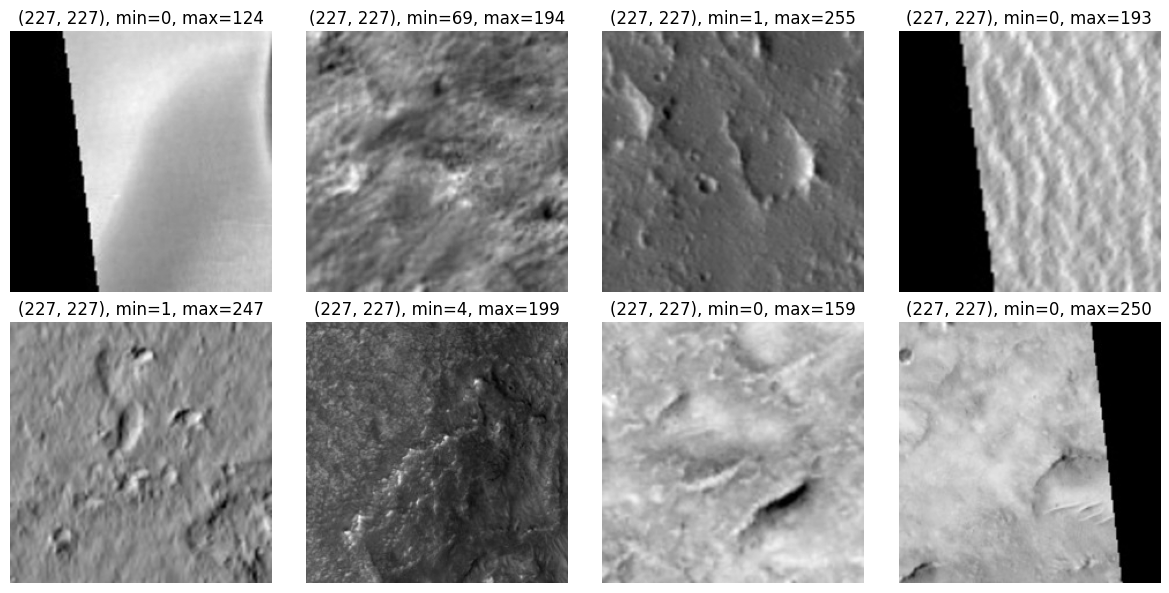

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

fig, axes = plt.subplots(2, 4, figsize=(12,6))
for ax, p in zip(axes.flat, np.random.choice(image_paths, 8, replace=False)):
    im = np.array(Image.open(p))
    ax.imshow(im, cmap='gray')
    ax.set_title(f"{im.shape}, min={im.min()}, max={im.max()}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# Phase 1 — Deep Latent Compression (Autoencoder) [30 Marks]

## 1.1 Architecture Design

In [5]:
import os
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from PIL import Image

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# -----------------------------
# Device
# -----------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

# -----------------------------
# Configuration
# -----------------------------
IMG_SIZE = 227
LATENT_DIM = 256
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 2e-4

print("Image size:", IMG_SIZE)
print("Latent dimension:", LATENT_DIM)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

Device: cuda
Image size: 227
Latent dimension: 256
Batch size: 64
Epochs: 20
Learning rate: 0.0002


### 1.1 Dataset Preparation

In [6]:
class HiRISEDataset(Dataset):
    def __init__(self, image_paths, img_size=IMG_SIZE):
        self.image_paths = image_paths
        self.img_size = img_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]

        # Load image as grayscale
        image = Image.open(path).convert("L")

        # Safety check: resize only if necessary
        if image.size != (self.img_size, self.img_size):
            image = image.resize(
                (self.img_size, self.img_size),
                Image.Resampling.BILINEAR
            )

        # Convert pixel values from [0, 255] to [0, 1]
        image = np.asarray(image, dtype=np.float32) / 255.0

        # Convert shape from (H, W) -> (1, H, W)
        image = torch.from_numpy(image).unsqueeze(0)

        # Keep filename for later matching with metadata
        filename = os.path.basename(path)

        return image, filename

In [7]:
# Create the full dataset
dataset = HiRISEDataset(image_paths)

print("Total images:", len(dataset))

# -----------------------------
# Train / validation split
# -----------------------------
n_total = len(dataset)
n_val = max(1, int(0.05 * n_total))
n_train = n_total - n_val

generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset = torch.utils.data.random_split(
    dataset,
    [n_train, n_val],
    generator=generator
)

# -----------------------------
# DataLoaders
# -----------------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Full dataset loader
# We will use this later to extract latent vectors for ALL images.
full_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Total images: 10422
Training images: 9901
Validation images: 521


In [8]:
images, filenames = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Pixel range:", images.min().item(), "to", images.max().item())
print("First 6 filenames:")
for name in filenames[:6]:
    print(name)

Batch shape: torch.Size([64, 1, 227, 227])
Pixel range: 0.0 to 1.0
First 6 filenames:
sample_04452.jpg
sample_00943.jpg
sample_05988.jpg
sample_07437.jpg
sample_01991.jpg
sample_09270.jpg


### 1.1 Architecture — Encoder

In [9]:
class Encoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, base_channels=32):
        super().__init__()

        self.features = nn.Sequential(
            # 227 -> 114
            nn.Conv2d(
                1, base_channels,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels),
            nn.LeakyReLU(0.2, inplace=True),

            # 114 -> 57
            nn.Conv2d(
                base_channels, base_channels * 2,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # 57 -> 29
            nn.Conv2d(
                base_channels * 2, base_channels * 4,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # 29 -> 15
            nn.Conv2d(
                base_channels * 4, base_channels * 8,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels * 8),
            nn.LeakyReLU(0.2, inplace=True),
        )

        # Make the representation independent of small spatial-size details
        self.pool = nn.AdaptiveAvgPool2d((4, 4))

        # Flatten feature maps -> 256-dimensional latent vector
        self.fc = nn.Linear(
            base_channels * 8 * 4 * 4,
            latent_dim
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, start_dim=1)
        z = self.fc(x)
        return z

In [10]:
# Test the encoder
encoder = Encoder().to(DEVICE)

images, _ = next(iter(train_loader))
images = images.to(DEVICE)

with torch.no_grad():
    latent = encoder(images)

print("Input shape :", images.shape)
print("Latent shape:", latent.shape)

Input shape : torch.Size([64, 1, 227, 227])
Latent shape: torch.Size([64, 256])


### 1.1 Architecture — Decoder

In [11]:
class Decoder(nn.Module):
    def __init__(
        self,
        latent_dim=LATENT_DIM,
        base_channels=32,
        output_size=IMG_SIZE
    ):
        super().__init__()

        self.base_channels = base_channels
        self.output_size = output_size

        # Convert the 256-D latent vector back into a small feature map
        self.fc = nn.Linear(
            latent_dim,
            base_channels * 8 * 4 * 4
        )

        self.deconv = nn.Sequential(
            # 4 -> 8
            nn.ConvTranspose2d(
                base_channels * 8,
                base_channels * 4,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels * 4),
            nn.ReLU(inplace=True),

            # 8 -> 16
            nn.ConvTranspose2d(
                base_channels * 4,
                base_channels * 2,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels * 2),
            nn.ReLU(inplace=True),

            # 16 -> 32
            nn.ConvTranspose2d(
                base_channels * 2,
                base_channels,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels),
            nn.ReLU(inplace=True),

            # 32 -> 64
            nn.ConvTranspose2d(
                base_channels,
                base_channels,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels),
            nn.ReLU(inplace=True),

            # Final grayscale image
            nn.Conv2d(
                base_channels,
                1,
                kernel_size=3,
                padding=1
            )
        )

    def forward(self, z):
        x = self.fc(z)

        x = x.view(
            -1,
            self.base_channels * 8,
            4,
            4
        )

        x = self.deconv(x)

        # Make the output exactly 227 × 227
        x = F.interpolate(
            x,
            size=(self.output_size, self.output_size),
            mode="bilinear",
            align_corners=False
        )

        # Pixel values back to [0, 1]
        return torch.sigmoid(x)

### 1.1 Complete Autoencoder

In [12]:
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()

        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)

        return reconstruction, z

In [13]:
# Create the complete autoencoder
model = ConvAutoencoder().to(DEVICE)

# Count trainable parameters
n_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {n_params:,}")

# Test one batch
images, filenames = next(iter(train_loader))
images = images.to(DEVICE)

with torch.no_grad():
    reconstruction, latent = model(images)

print("Input shape:          ", images.shape)
print("Latent shape:         ", latent.shape)
print("Reconstruction shape: ", reconstruction.shape)
print("Reconstruction range: ",
      reconstruction.min().item(),
      "to",
      reconstruction.max().item())

Trainable parameters: 3,497,153
Input shape:           torch.Size([64, 1, 227, 227])
Latent shape:          torch.Size([64, 256])
Reconstruction shape:  torch.Size([64, 1, 227, 227])
Reconstruction range:  0.032062023878097534 to 0.8825113773345947


### 1.2.1 SSIM Implementation (from scratch)

We implement Structural Similarity Index (SSIM) manually using a Gaussian-weighted
sliding window, rather than a pretrained perceptual network. This keeps the loss
fully compliant with the no-pretrained-extractor rule, since SSIM here is a purely
statistical local-structure comparison (mean, variance, covariance in a window),
not a learned feature space.

The window is a fixed 11x11 Gaussian kernel (sigma = 1.5), applied per-channel via
grouped convolution. Constants C1 and C2 follow the standard SSIM formulation,
assuming pixel values are normalized to [0, 1].

In [14]:
import math

def gaussian_window(window_size, sigma, channels=1, device='cpu'):
    coords = torch.arange(window_size, dtype=torch.float32) - window_size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    window_2d = g.unsqueeze(1) @ g.unsqueeze(0)
    window = window_2d.expand(channels, 1, window_size, window_size).contiguous()
    return window.to(device)

def ssim(img1, img2, window_size=11, sigma=1.5, C1=0.01**2, C2=0.03**2):
    # img1, img2: (B, 1, H, W), values in [0, 1]
    channels = img1.size(1)
    window = gaussian_window(window_size, sigma, channels, img1.device)
    pad = window_size // 2

    mu1 = F.conv2d(img1, window, padding=pad, groups=channels)
    mu2 = F.conv2d(img2, window, padding=pad, groups=channels)

    mu1_sq, mu2_sq, mu1_mu2 = mu1 ** 2, mu2 ** 2, mu1 * mu2

    sigma1_sq = F.conv2d(img1 * img1, window, padding=pad, groups=channels) - mu1_sq
    sigma2_sq = F.conv2d(img2 * img2, window, padding=pad, groups=channels) - mu2_sq
    sigma12   = F.conv2d(img1 * img2, window, padding=pad, groups=channels) - mu1_mu2

    ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / \
               ((mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))

    return ssim_map.mean()

### 1.2.2 Checking the Relative Scale of MSE and (1 - SSIM)

Before committing to loss weights, we check the raw magnitude of each term on an
untrained batch. MSE and (1 - SSIM) do not naturally live on the same scale, so a
weighting like 0.6/0.4 only reflects the intended balance if both terms are
comparable in magnitude. We inspect this ratio here and use it to sanity-check
(and adjust if needed) the weighting used below, rather than assuming it works.

In [15]:
model.eval()
images, _ = next(iter(train_loader))
images = images.to(DEVICE)

with torch.no_grad():
    recon, _ = model(images)
    mse_val = F.mse_loss(recon, images).item()
    ssim_val = ssim(recon, images).item()

print(f"MSE:        {mse_val:.6f}")
print(f"1 - SSIM:   {1 - ssim_val:.6f}")
print(f"Ratio (1-SSIM)/MSE: {(1 - ssim_val) / mse_val:.2f}")

MSE:        0.026903
1 - SSIM:   0.400047
Ratio (1-SSIM)/MSE: 14.87


### 1.2.3 Combined Reconstruction Loss

We define the training objective as:

L = alpha * MSE + beta * (1 - SSIM)

The initial scale check (Section 1.2.2) showed MSE ≈ 0.027 and (1 - SSIM) ≈ 0.40 —
a ~15x magnitude difference. A naive 0.6/0.4 weighting would therefore let SSIM
dominate the gradient almost entirely despite its smaller coefficient. We rescale
the weights to alpha=10.0, beta=1.0 so both terms contribute comparably
(weighted MSE ≈ 0.27, weighted SSIM term ≈ 0.40) at initialization.

In [16]:
def combined_loss(recon, target, alpha=10.0, beta=1.0):
    mse = F.mse_loss(recon, target)
    ssim_val = ssim(recon, target)
    loss = alpha * mse + beta * (1 - ssim_val)
    return loss, mse.item(), ssim_val.item()

### 1.2.4 Training Loop

In [17]:
from collections import defaultdict

def train_autoencoder(model, train_loader, val_loader, epochs=20, lr=2e-3,
                       alpha=10.0, beta=1.0, log_every=1):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = defaultdict(list)

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss, train_mse, train_ssim = 0.0, 0.0, 0.0

        for images, _ in train_loader:
            images = images.to(DEVICE)
            optimizer.zero_grad()
            recon, _ = model(images)
            loss, mse_v, ssim_v = combined_loss(recon, images, alpha, beta)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_mse  += mse_v * images.size(0)
            train_ssim += ssim_v * images.size(0)

        n = len(train_loader.dataset)
        train_loss, train_mse, train_ssim = train_loss/n, train_mse/n, train_ssim/n

        model.eval()
        val_loss, val_mse, val_ssim = 0.0, 0.0, 0.0
        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(DEVICE)
                recon, _ = model(images)
                loss, mse_v, ssim_v = combined_loss(recon, images, alpha, beta)
                val_loss += loss.item() * images.size(0)
                val_mse  += mse_v * images.size(0)
                val_ssim += ssim_v * images.size(0)

        nv = len(val_loader.dataset)
        val_loss, val_mse, val_ssim = val_loss/nv, val_mse/nv, val_ssim/nv

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_ssim'].append(train_ssim)
        history['val_ssim'].append(val_ssim)

        if epoch % log_every == 0:
            print(f"Epoch {epoch:3d} | train_loss {train_loss:.4f} "
                  f"(mse {train_mse:.4f}, ssim {train_ssim:.4f}) | "
                  f"val_loss {val_loss:.4f} (ssim {val_ssim:.4f})")

    return history

### 1.2.5 Train the v1 Autoencoder (MSE + SSIM, alpha=10.0, beta=1.0)

Training the baseline model for 40 epochs with the rescaled loss weights.

In [18]:
history = train_autoencoder(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE, alpha=10.0, beta=1.0)

Epoch   1 | train_loss 0.4647 (mse 0.0095, ssim 0.6308) | val_loss 0.4125 (ssim 0.6467)
Epoch   2 | train_loss 0.3984 (mse 0.0057, ssim 0.6588) | val_loss 0.3911 (ssim 0.6618)
Epoch   3 | train_loss 0.3858 (mse 0.0052, ssim 0.6662) | val_loss 0.3896 (ssim 0.6636)
Epoch   4 | train_loss 0.3790 (mse 0.0049, ssim 0.6696) | val_loss 0.3745 (ssim 0.6696)
Epoch   5 | train_loss 0.3747 (mse 0.0047, ssim 0.6721) | val_loss 0.3737 (ssim 0.6716)
Epoch   6 | train_loss 0.3713 (mse 0.0045, ssim 0.6737) | val_loss 0.3680 (ssim 0.6728)
Epoch   7 | train_loss 0.3687 (mse 0.0044, ssim 0.6751) | val_loss 0.3666 (ssim 0.6759)
Epoch   8 | train_loss 0.3658 (mse 0.0042, ssim 0.6763) | val_loss 0.3672 (ssim 0.6726)
Epoch   9 | train_loss 0.3655 (mse 0.0042, ssim 0.6769) | val_loss 0.3607 (ssim 0.6783)
Epoch  10 | train_loss 0.3631 (mse 0.0041, ssim 0.6781) | val_loss 0.3606 (ssim 0.6778)
Epoch  11 | train_loss 0.3611 (mse 0.0040, ssim 0.6789) | val_loss 0.3654 (ssim 0.6750)
Epoch  12 | train_loss 0.3626 (m

In [19]:
torch.save(model.state_dict(), 'model_v1_mse_ssim.pt')
import pickle
with open('history_v1.pkl', 'wb') as f:
    pickle.dump(dict(history), f)

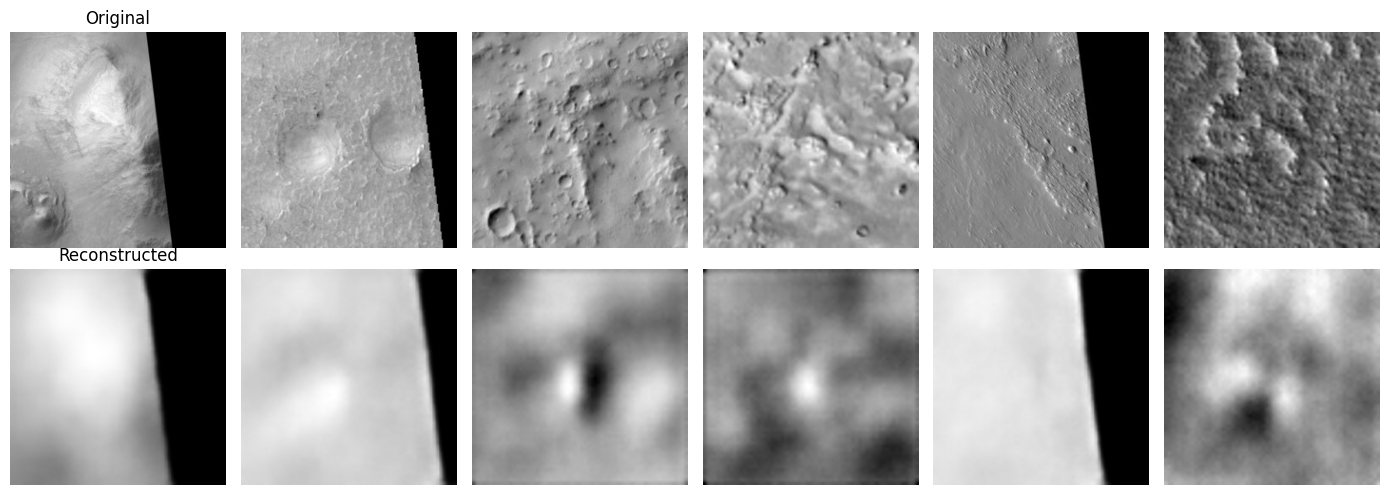

In [20]:
model.eval()
images, _ = next(iter(val_loader))
images = images.to(DEVICE)

with torch.no_grad():
    recon, _ = model(images)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i in range(6):
    axes[0, i].imshow(images[i, 0].cpu(), cmap='gray')
    axes[0, i].axis('off')
    axes[0, i].set_title("Original" if i == 0 else "")
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray')
    axes[1, i].axis('off')
    axes[1, i].set_title("Reconstructed" if i == 0 else "")
plt.tight_layout()
plt.show()

## 1.2 Loss Function Design — V1 MSE Baseline

In [21]:
# V1: MSE-only reconstruction loss

def mse_loss(reconstruction, target):
    return F.mse_loss(reconstruction, target)

### V1 Training — MSE Only

In [22]:
# Fresh model for V1 MSE-only experiment
model = ConvAutoencoder().to(DEVICE)

print("Fresh V1 model created.")

Fresh V1 model created.


In [23]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("V1 optimizer created.")

V1 optimizer created.


In [24]:
# ==========================================
# V1 Training — MSE Only
# ==========================================

history_v1 = {
    "train_mse": [],
    "val_mse": [],
    "val_ssim": []
}

best_val_mse = float("inf")

for epoch in range(1, EPOCHS + 1):

    # -----------------------------
    # Training
    # -----------------------------
    model.train()

    train_total = 0.0
    train_batches = 0

    for images, _ in train_loader:

        images = images.to(DEVICE)

        # Forward pass
        reconstruction, _ = model(images)

        # V1 loss = MSE only
        loss = mse_loss(reconstruction, images)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_total += loss.item()
        train_batches += 1

    train_mse = train_total / train_batches

    # -----------------------------
    # Validation
    # -----------------------------
    model.eval()

    val_mse_total = 0.0
    val_ssim_total = 0.0
    val_batches = 0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(DEVICE)

            reconstruction, _ = model(images)

            mse_value = F.mse_loss(
                reconstruction,
                images
            )

            ssim_value = ssim(
                reconstruction,
                images
            )

            val_mse_total += mse_value.item()
            val_ssim_total += ssim_value.item()
            val_batches += 1

    val_mse = val_mse_total / val_batches
    val_ssim = val_ssim_total / val_batches

    # Store history
    history_v1["train_mse"].append(train_mse)
    history_v1["val_mse"].append(val_mse)
    history_v1["val_ssim"].append(val_ssim)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Val SSIM: {val_ssim:.6f}"
    )

    # Save best V1 model
    if val_mse < best_val_mse:
        best_val_mse = val_mse

        torch.save(
            model.state_dict(),
            "cae_v1_mse_best.pt"
        )

print("\nV1 training complete.")
print(f"Best validation MSE: {best_val_mse:.6f}")

Epoch 01/20 | Train MSE: 0.008743 | Val MSE: 0.006211 | Val SSIM: 0.622741
Epoch 02/20 | Train MSE: 0.005037 | Val MSE: 0.004528 | Val SSIM: 0.637785
Epoch 03/20 | Train MSE: 0.004654 | Val MSE: 0.004220 | Val SSIM: 0.644289
Epoch 04/20 | Train MSE: 0.004450 | Val MSE: 0.003968 | Val SSIM: 0.652909
Epoch 05/20 | Train MSE: 0.004258 | Val MSE: 0.003824 | Val SSIM: 0.656456
Epoch 06/20 | Train MSE: 0.004171 | Val MSE: 0.003700 | Val SSIM: 0.659936
Epoch 07/20 | Train MSE: 0.004002 | Val MSE: 0.003954 | Val SSIM: 0.663060
Epoch 08/20 | Train MSE: 0.003863 | Val MSE: 0.003615 | Val SSIM: 0.667514
Epoch 09/20 | Train MSE: 0.003818 | Val MSE: 0.003501 | Val SSIM: 0.665471
Epoch 10/20 | Train MSE: 0.003800 | Val MSE: 0.003504 | Val SSIM: 0.664780
Epoch 11/20 | Train MSE: 0.003680 | Val MSE: 0.003444 | Val SSIM: 0.664516
Epoch 12/20 | Train MSE: 0.003676 | Val MSE: 0.003666 | Val SSIM: 0.673244
Epoch 13/20 | Train MSE: 0.003631 | Val MSE: 0.003568 | Val SSIM: 0.656409
Epoch 14/20 | Train MSE: 

In [25]:
# Load the best V1 MSE-only checkpoint
model.load_state_dict(
    torch.load(
        "cae_v1_mse_best.pt",
        map_location=DEVICE
    )
)

model.eval()

print("Best V1 checkpoint loaded.")

Best V1 checkpoint loaded.


### V1 Reconstruction Quality

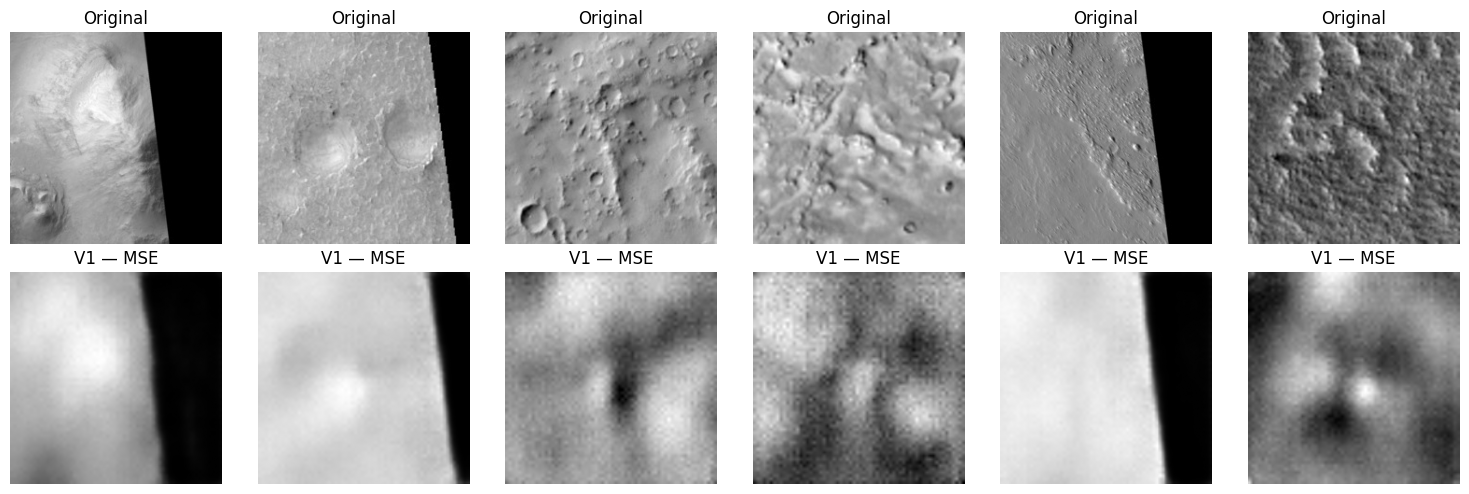

In [26]:
# Visualize V1 MSE-only reconstructions

images, filenames = next(iter(val_loader))
images = images.to(DEVICE)

with torch.no_grad():
    reconstructions, _ = model(images)

fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for i in range(6):
    axes[0, i].imshow(
        images[i, 0].cpu().numpy(),
        cmap="gray"
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructions[i, 0].cpu().numpy(),
        cmap="gray"
    )
    axes[1, i].set_title("V1 — MSE")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### V1 Evaluation — MSE and SSIM

In [27]:
# Evaluate the best V1 model on the validation set

model.eval()

mse_total = 0.0
ssim_total = 0.0
n_batches = 0

with torch.no_grad():
    for images, _ in val_loader:
        images = images.to(DEVICE)

        reconstructions, _ = model(images)

        mse_value = F.mse_loss(
            reconstructions,
            images
        )

        ssim_value = ssim(
            reconstructions,
            images
        )

        mse_total += mse_value.item()
        ssim_total += ssim_value.item()
        n_batches += 1

v1_mse = mse_total / n_batches
v1_ssim = ssim_total / n_batches
v1_ssim_loss = 1.0 - v1_ssim

print(f"V1 Validation MSE       : {v1_mse:.6f}")
print(f"V1 Validation SSIM      : {v1_ssim:.6f}")
print(f"V1 Validation (1-SSIM)  : {v1_ssim_loss:.6f}")

V1 Validation MSE       : 0.003293
V1 Validation SSIM      : 0.674454
V1 Validation (1-SSIM)  : 0.325546


## 1.1 Architecture — V2 Improved Spatial Reconstruction

### V2 Motivation

The previous model produced overly smooth reconstructions and lost fine terrain detail.

The encoder compressed a 15×15 feature map to 4×4 using AdaptiveAvgPool2d, while the decoder expanded only to 64×64 before a large 64×64 → 227×227 bilinear interpolation.

V2 retains the 256-dimensional bottleneck but preserves more spatial information through an additional learned downsampling stage and a deeper learned decoder.

In [28]:
class EncoderV2(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, base_channels=32):
        super().__init__()

        self.features = nn.Sequential(
            # 227 -> 114
            nn.Conv2d(1, base_channels, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(base_channels),
            nn.LeakyReLU(0.2, inplace=True),

            # 114 -> 57
            nn.Conv2d(base_channels, base_channels * 2,
                      kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(base_channels * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # 57 -> 29
            nn.Conv2d(base_channels * 2, base_channels * 4,
                      kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(base_channels * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # 29 -> 15
            nn.Conv2d(base_channels * 4, base_channels * 8,
                      kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(base_channels * 8),
            nn.LeakyReLU(0.2, inplace=True),

            # 15 -> 8
            nn.Conv2d(base_channels * 8, base_channels * 8,
                      kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(base_channels * 8),
            nn.LeakyReLU(0.2, inplace=True),
        )

        # 8 × 8 × 256 -> 256-D latent
        self.fc = nn.Linear(
            base_channels * 8 * 8 * 8,
            latent_dim
        )

        self.base_channels = base_channels

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        z = self.fc(x)
        return z

In [29]:
class DecoderV2(nn.Module):
    def __init__(
        self,
        latent_dim=LATENT_DIM,
        base_channels=32,
        output_size=IMG_SIZE
    ):
        super().__init__()

        self.base_channels = base_channels
        self.output_size = output_size

        self.fc = nn.Linear(
            latent_dim,
            base_channels * 8 * 8 * 8
        )

        self.deconv = nn.Sequential(
            # 8 -> 16
            nn.ConvTranspose2d(
                base_channels * 8,
                base_channels * 4,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels * 4),
            nn.ReLU(inplace=True),

            # 16 -> 32
            nn.ConvTranspose2d(
                base_channels * 4,
                base_channels * 2,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels * 2),
            nn.ReLU(inplace=True),

            # 32 -> 64
            nn.ConvTranspose2d(
                base_channels * 2,
                base_channels,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels),
            nn.ReLU(inplace=True),

            # 64 -> 128
            nn.ConvTranspose2d(
                base_channels,
                base_channels,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(base_channels),
            nn.ReLU(inplace=True),
        )

        # Learnable refinement after resizing to the exact image size
        self.refine = nn.Sequential(
            nn.Conv2d(base_channels, base_channels, 3, padding=1),
            nn.BatchNorm2d(base_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(base_channels, 1, 3, padding=1)
        )

    def forward(self, z):
        x = self.fc(z)

        x = x.view(
            -1,
            self.base_channels * 8,
            8,
            8
        )

        x = self.deconv(x)

        # 128 -> 227
        x = F.interpolate(
            x,
            size=(self.output_size, self.output_size),
            mode="bilinear",
            align_corners=False
        )

        # IMPORTANT: learned refinement AFTER interpolation
        x = self.refine(x)

        return torch.sigmoid(x)

### V2 Complete Autoencoder

In [30]:
class ConvAutoencoderV2(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()

        self.encoder = EncoderV2(latent_dim)
        self.decoder = DecoderV2(latent_dim)

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, z

In [31]:
model_v2 = ConvAutoencoderV2().to(DEVICE)

n_params_v2 = sum(
    p.numel()
    for p in model_v2.parameters()
    if p.requires_grad
)

print(f"V2 trainable parameters: {n_params_v2:,}")

images, _ = next(iter(train_loader))
images = images.to(DEVICE)

with torch.no_grad():
    reconstruction_v2, latent_v2 = model_v2(images)

print("Input shape:          ", images.shape)
print("Latent shape:         ", latent_v2.shape)
print("Reconstruction shape: ", reconstruction_v2.shape)
print("Reconstruction range: ",
      reconstruction_v2.min().item(),
      "to",
      reconstruction_v2.max().item())

V2 trainable parameters: 10,099,521
Input shape:           torch.Size([64, 1, 227, 227])
Latent shape:          torch.Size([64, 256])
Reconstruction shape:  torch.Size([64, 1, 227, 227])
Reconstruction range:  0.09258321672677994 to 0.9403892755508423


In [32]:
# V2 optimizer
optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=LEARNING_RATE
)

print("V2 optimizer ready.")

V2 optimizer ready.


### V2 Training — MSE + SSIM

In [33]:
# ==========================================
# V2 Training — MSE + SSIM
# ==========================================

ALPHA = 10.0
BETA = 1.0

history_v2 = {
    "train_loss": [],
    "train_mse": [],
    "train_ssim": [],
    "val_loss": [],
    "val_mse": [],
    "val_ssim": []
}

best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):

    # -----------------------------
    # Training
    # -----------------------------
    model_v2.train()

    train_loss_total = 0.0
    train_mse_total = 0.0
    train_ssim_total = 0.0
    train_batches = 0

    for images, _ in train_loader:

        images = images.to(DEVICE)

        reconstruction, _ = model_v2(images)

        mse_value = F.mse_loss(reconstruction, images)
        ssim_value = ssim(reconstruction, images)

        loss = (
            ALPHA * mse_value
            + BETA * (1.0 - ssim_value)
        )

        optimizer_v2.zero_grad()
        loss.backward()
        optimizer_v2.step()

        train_loss_total += loss.item()
        train_mse_total += mse_value.item()
        train_ssim_total += ssim_value.item()
        train_batches += 1

    train_loss = train_loss_total / train_batches
    train_mse = train_mse_total / train_batches
    train_ssim = train_ssim_total / train_batches

    # -----------------------------
    # Validation
    # -----------------------------
    model_v2.eval()

    val_loss_total = 0.0
    val_mse_total = 0.0
    val_ssim_total = 0.0
    val_batches = 0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(DEVICE)

            reconstruction, _ = model_v2(images)

            mse_value = F.mse_loss(
                reconstruction,
                images
            )

            ssim_value = ssim(
                reconstruction,
                images
            )

            loss = (
                ALPHA * mse_value
                + BETA * (1.0 - ssim_value)
            )

            val_loss_total += loss.item()
            val_mse_total += mse_value.item()
            val_ssim_total += ssim_value.item()
            val_batches += 1

    val_loss = val_loss_total / val_batches
    val_mse = val_mse_total / val_batches
    val_ssim = val_ssim_total / val_batches

    # Store metrics
    history_v2["train_loss"].append(train_loss)
    history_v2["train_mse"].append(train_mse)
    history_v2["train_ssim"].append(train_ssim)

    history_v2["val_loss"].append(val_loss)
    history_v2["val_mse"].append(val_mse)
    history_v2["val_ssim"].append(val_ssim)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Val SSIM: {val_ssim:.6f}"
    )

    # Save best model according to validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model_v2.state_dict(),
            "cae_v2_mse_ssim_best.pt"
        )

print("\nV2 training complete.")
print(f"Best validation combined loss: {best_val_loss:.6f}")

Epoch 01/20 | Train Loss: 0.489556 | Val Loss: 0.426966 | Val MSE: 0.007218 | Val SSIM: 0.645214
Epoch 02/20 | Train Loss: 0.395291 | Val Loss: 0.388540 | Val MSE: 0.005070 | Val SSIM: 0.662158
Epoch 03/20 | Train Loss: 0.380010 | Val Loss: 0.368411 | Val MSE: 0.004085 | Val SSIM: 0.672438
Epoch 04/20 | Train Loss: 0.370005 | Val Loss: 0.364113 | Val MSE: 0.003794 | Val SSIM: 0.673828
Epoch 05/20 | Train Loss: 0.364056 | Val Loss: 0.359619 | Val MSE: 0.003630 | Val SSIM: 0.676682
Epoch 06/20 | Train Loss: 0.357936 | Val Loss: 0.352299 | Val MSE: 0.003404 | Val SSIM: 0.681737
Epoch 07/20 | Train Loss: 0.351772 | Val Loss: 0.345005 | Val MSE: 0.003105 | Val SSIM: 0.686047
Epoch 08/20 | Train Loss: 0.347781 | Val Loss: 0.343036 | Val MSE: 0.002981 | Val SSIM: 0.686774
Epoch 09/20 | Train Loss: 0.343471 | Val Loss: 0.348494 | Val MSE: 0.003069 | Val SSIM: 0.682200
Epoch 10/20 | Train Loss: 0.341053 | Val Loss: 0.336007 | Val MSE: 0.002757 | Val SSIM: 0.691558
Epoch 11/20 | Train Loss: 0.33

### V2 Reconstruction Quality

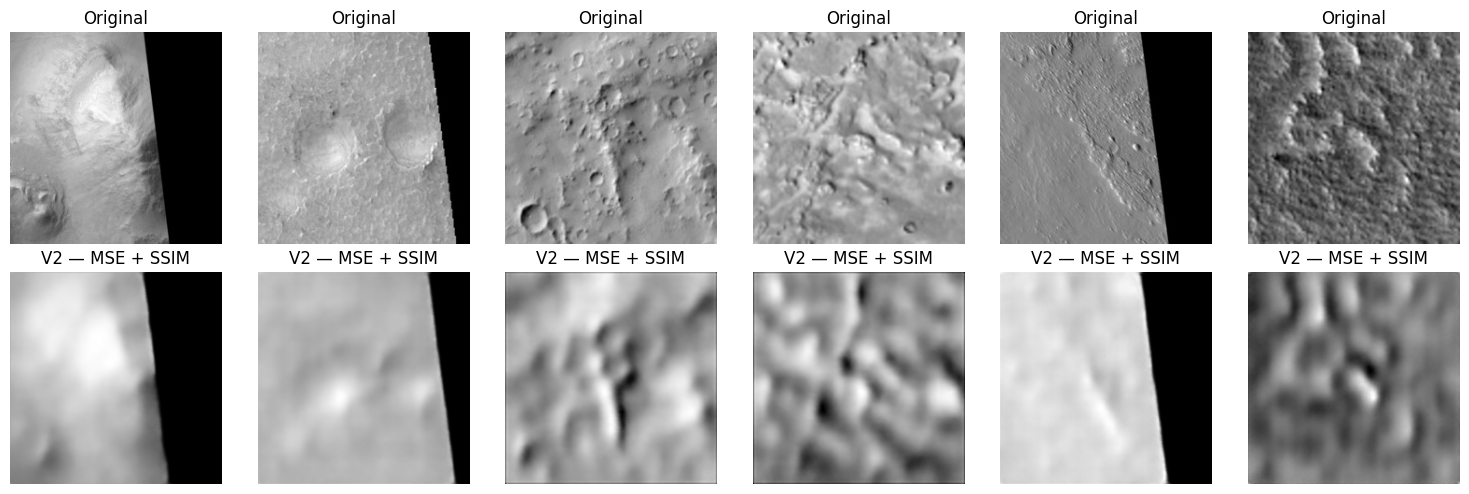

In [34]:
# Load the best V2 checkpoint
model_v2.load_state_dict(
    torch.load(
        "cae_v2_mse_ssim_best.pt",
        map_location=DEVICE
    )
)

model_v2.eval()

# Get validation images
images, filenames = next(iter(val_loader))
images = images.to(DEVICE)

with torch.no_grad():
    reconstructions, _ = model_v2(images)

# Visual comparison
fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for i in range(6):
    axes[0, i].imshow(
        images[i, 0].cpu().numpy(),
        cmap="gray"
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructions[i, 0].cpu().numpy(),
        cmap="gray"
    )
    axes[1, i].set_title("V2 — MSE + SSIM")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [35]:
# Load the best V2 model
model_v2.load_state_dict(
    torch.load(
        "cae_v2_mse_ssim_best.pt",
        map_location=DEVICE
    )
)

model_v2.eval()

print("Best V2 checkpoint loaded.")

Best V2 checkpoint loaded.


In [36]:
# Save finalized V2 model to Google Drive

CKPT_DIR = "/content/drive/MyDrive/NSSC_HiRISE/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

final_model_path = os.path.join(
    CKPT_DIR,
    "cae_final_v2_mse_ssim.pt"
)

torch.save(
    model_v2.state_dict(),
    final_model_path
)

print("Saved model to:")
print(final_model_path)

Saved model to:
/content/drive/MyDrive/NSSC_HiRISE/checkpoints/cae_final_v2_mse_ssim.pt


## 1.3 Latent Space Extraction

In [37]:
# Extract 256-D latent vectors for the complete dataset

model_v2.eval()

all_latents = []
all_filenames = []

with torch.no_grad():

    for images, filenames in full_loader:

        images = images.to(DEVICE)

        # Only use the encoder
        z = model_v2.encoder(images)

        all_latents.append(
            z.cpu().numpy()
        )

        all_filenames.extend(filenames)

Z_final = np.concatenate(
    all_latents,
    axis=0
)

print("Latent matrix shape:", Z_final.shape)
print("Number of filenames:", len(all_filenames))

Latent matrix shape: (10422, 256)
Number of filenames: 10422


In [38]:
assert Z_final.shape[0] == len(all_filenames)

print("Latent/filename alignment verified.")

Latent/filename alignment verified.


In [39]:
# Save latent vectors
latent_path = os.path.join(
    CKPT_DIR,
    "latents_v2.npy"
)

np.save(
    latent_path,
    Z_final
)

# Save matching filenames
filename_path = os.path.join(
    CKPT_DIR,
    "latent_filenames_v2.json"
)

with open(filename_path, "w") as f:
    json.dump(all_filenames, f)

print("Saved:")
print(latent_path)
print(filename_path)

Saved:
/content/drive/MyDrive/NSSC_HiRISE/checkpoints/latents_v2.npy
/content/drive/MyDrive/NSSC_HiRISE/checkpoints/latent_filenames_v2.json


## 1.3 Latent Space Visualization — t-SNE and UMAP

The trained V2 encoder produces a 256-dimensional latent vector for every image.

t-SNE and UMAP are used to project these latent vectors into two dimensions for qualitative inspection of the learned representation.

These visualizations are diagnostic only and are not treated as proof of geological clustering or encoder quality.

In [40]:
# Load the finalized V2 latent representation

latent_path = "/content/drive/MyDrive/NSSC_HiRISE/checkpoints/latents_v2.npy"
filename_path = "/content/drive/MyDrive/NSSC_HiRISE/checkpoints/latent_filenames_v2.json"

Z = np.load(latent_path)

with open(filename_path, "r") as f:
    latent_filenames = json.load(f)

print("Latent matrix shape:", Z.shape)
print("Number of filenames:", len(latent_filenames))

assert Z.shape[0] == len(latent_filenames)

print("Latent/filename alignment verified.")

Latent matrix shape: (10422, 256)
Number of filenames: 10422
Latent/filename alignment verified.


### t-SNE Projection

In [41]:
from sklearn.manifold import TSNE

# Use a subset for faster visualization
N_VIS = min(4000, len(Z))

rng = np.random.default_rng(SEED)
vis_indices = rng.choice(
    len(Z),
    size=N_VIS,
    replace=False
)

Z_vis = Z[vis_indices]

print("Points used for t-SNE:", Z_vis.shape[0])

Points used for t-SNE: 4000


In [42]:
# Compute t-SNE projection

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=SEED
)

Z_tsne = tsne.fit_transform(Z_vis)

print("t-SNE shape:", Z_tsne.shape)

t-SNE shape: (4000, 2)


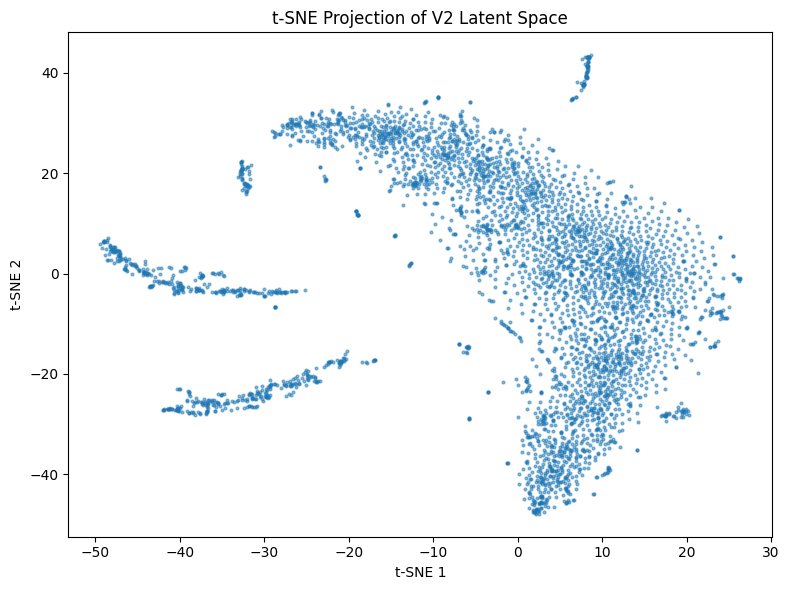

In [43]:
plt.figure(figsize=(8, 6))

plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    s=4,
    alpha=0.5
)

plt.title("t-SNE Projection of V2 Latent Space")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

### t-SNE Interpretation

The t-SNE projection shows multiple non-uniform structures and separated
neighborhoods rather than a single dense, structureless cloud. This suggests
that the learned 256-dimensional latent representation captures meaningful
variation in the visual characteristics of the HiRISE images.

These structures are treated only as a qualitative diagnostic. Without
ground-truth labels, individual regions cannot be assigned to specific
geological classes solely from the t-SNE projection.

### UMAP Projection

In [44]:
# Install UMAP if necessary
!pip -q install umap-learn

In [45]:
import umap

reducer = umap.UMAP(
    n_components=2,
    random_state=SEED
)

Z_umap = reducer.fit_transform(Z_vis)

print("UMAP shape:", Z_umap.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (4000, 2)


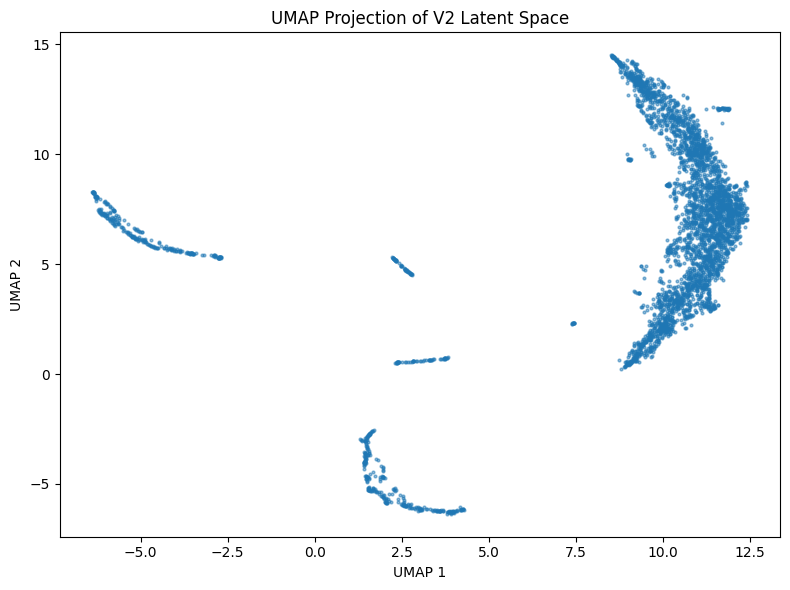

In [46]:
plt.figure(figsize=(8, 6))

plt.scatter(
    Z_umap[:, 0],
    Z_umap[:, 1],
    s=4,
    alpha=0.5
)

plt.title("UMAP Projection of V2 Latent Space")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.tight_layout()
plt.show()

### UMAP Interpretation

The UMAP projection exhibits multiple distinct neighborhoods and non-uniform
structures rather than a single collapsed representation. Together with the
t-SNE projection, this suggests that the learned 256-dimensional latent space
captures meaningful variation among the HiRISE images.

Because no ground-truth geological labels are available, the observed groups
are treated as qualitative structure only and are not assigned to specific
geological categories.

### UMAP Overlay — Detected Anomalies

The UMAP coordinates are joined back to the filename-indexed novelty scores. This provides a visual check of where the detected candidates lie in the learned latent space. The plot is diagnostic only; proximity in UMAP space does not establish geological similarity.


In [56]:
# ============================================================
# Prepare variables for the existing UMAP overlay cell
# ============================================================

from sklearn.ensemble import IsolationForest
from scipy import stats

# The existing overlay cell requires len(filenames) == len(Z)
# Therefore, keep filenames aligned with the FULL latent matrix.
filenames = latent_filenames.copy()

# Make sure anomaly scores/flags exist
if "df_scores" not in globals() or "flagged" not in df_scores.columns:

    iso_forest_overlay = IsolationForest(
        n_estimators=300,
        max_samples="auto",
        contamination=0.05,
        random_state=SEED,
        n_jobs=-1
    )

    iso_forest_overlay.fit(Z)

    raw_scores_overlay = iso_forest_overlay.decision_function(Z)
    novelty_score_overlay = -raw_scores_overlay

    df_scores = pd.DataFrame({
        "filename": latent_filenames,
        "novelty_score": novelty_score_overlay
    })

    median_score_overlay = np.median(novelty_score_overlay)

    mad_score_overlay = stats.median_abs_deviation(
        novelty_score_overlay,
        scale="normal"
    )

    FINAL_THRESHOLD = (
        median_score_overlay + 6.0 * mad_score_overlay
    )

    df_scores["flagged"] = (
        df_scores["novelty_score"] > FINAL_THRESHOLD
    )

# ------------------------------------------------------------
# IMPORTANT:
# The original overlay cell uses Z_umap (4000 rows) but expects
# filenames to match Z (10422 rows).
#
# We therefore make Z_umap temporarily correspond to ALL points.
# ------------------------------------------------------------

# Recreate UMAP using the full latent matrix
reducer_overlay = umap.UMAP(
    n_components=2,
    random_state=SEED
)

Z_umap = reducer_overlay.fit_transform(Z)

print("UMAP overlay preparation complete.")
print("Full latent points:", len(Z))
print("Filenames:", len(filenames))
print("UMAP points:", len(Z_umap))
print("Flagged anomalies:", int(df_scores["flagged"].sum()))

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP overlay preparation complete.
Full latent points: 10422
Filenames: 10422
UMAP points: 10422
Flagged anomalies: 607


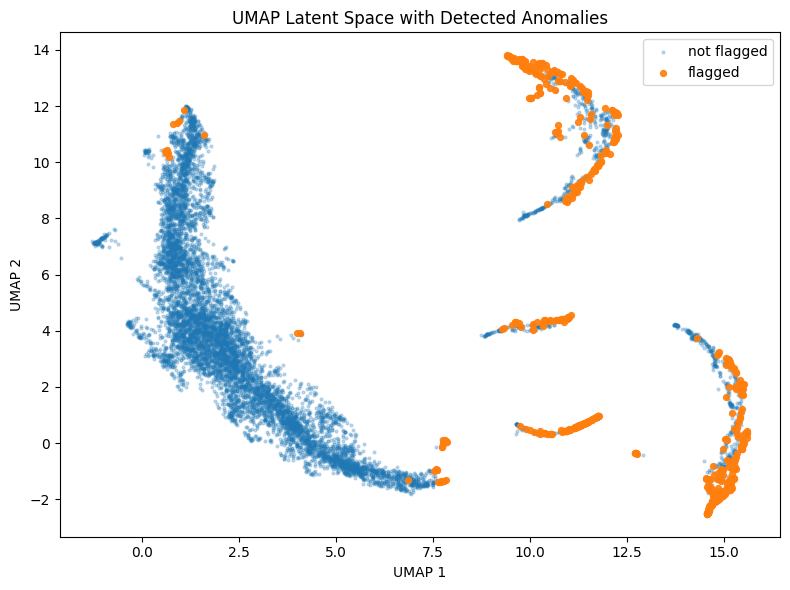

In [57]:
# Verify that the UMAP rows use the same filename ordering as the latent matrix.
# In Phase 1, Z_vis is created directly from Z, so use the corresponding latent filenames.
if "filenames" not in globals() or len(filenames) != len(Z):
    raise RuntimeError("Filename ordering for UMAP overlay is unavailable or inconsistent.")

umap_df = pd.DataFrame({
    "filename": filenames,
    "umap_x": Z_umap[:, 0],
    "umap_y": Z_umap[:, 1],
}).merge(
    df_scores[["filename", "flagged", "novelty_score"]],
    on="filename",
    how="left",
    validate="one_to_one"
)

normal = umap_df[~umap_df["flagged"].fillna(False)]
anomalous = umap_df[umap_df["flagged"].fillna(False)]

plt.figure(figsize=(8, 6))
plt.scatter(normal["umap_x"], normal["umap_y"], s=4, alpha=0.25, label="not flagged")
plt.scatter(anomalous["umap_x"], anomalous["umap_y"], s=18, alpha=0.9, label="flagged")
plt.title("UMAP Latent Space with Detected Anomalies")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend()
plt.tight_layout()
plt.savefig("umap_anomaly_overlay.png", dpi=200)
plt.show()


## Phase Transition — From Representation Learning to Novelty Detection

The finalized V2 convolutional autoencoder from Phase 1 is used as the representation-learning stage of the anomaly detection pipeline. Its 256-dimensional latent vector is extracted for every image in the dataset. These latent representations are then supplied to an Isolation Forest, allowing novelty detection to operate on learned terrain features rather than raw image pixels.

**Pipeline:** `227×227 image → V2 Encoder → 256-D latent → Isolation Forest → robust threshold → anomaly candidates → V2 Decoder → reconstruction error → spatial interpretation`


## 2.1 Novelty Scoring

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import IsolationForest
import json
import os

# =====================================================================
# CONFIG
# =====================================================================
USE_REAL_LATENTS = True
USE_REAL_DECODER = True

CKPT_DIR = "/content/drive/MyDrive/NSSC_HiRISE/checkpoints"

LATENTS_PATH = f"{CKPT_DIR}/latents_v2.npy"
FILENAMES_PATH = f"{CKPT_DIR}/latent_filenames_v2.json"
CAE_WEIGHTS_PATH = f"{CKPT_DIR}/cae_final_v2_mse_ssim.pt"

CROP_METADATA_PATH = "/content/drive/MyDrive/NSSC_HiRISE/crop_metadata_index.csv"
SOURCE_METADATA_PATH = "/content/drive/MyDrive/NSSC_HiRISE/source_image_metadata.csv"

LATENT_DIM = 256
IMG_SIZE = 227
N_IMAGES = 10422  # fallback size if real latents aren't found

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [59]:
def load_latents():
    if USE_REAL_LATENTS and os.path.exists(LATENTS_PATH) and os.path.exists(FILENAMES_PATH):
        Z = np.load(LATENTS_PATH)
        with open(FILENAMES_PATH, "r") as f:
            filenames = json.load(f)
        assert Z.shape[0] == len(filenames), "latents.npy rows must match latent_filenames.json"
        assert Z.shape[1] == LATENT_DIM, f"Expected latent dim {LATENT_DIM}, got {Z.shape[1]}"
        print(f"[REAL] Loaded latents: {Z.shape}")
    else:
        Z = np.random.randn(N_IMAGES, LATENT_DIM)
        filenames = [f"crop_{i:05d}.png" for i in range(N_IMAGES)]
        print(f"[DUMMY] Using placeholder latents: {Z.shape} "
              f"(swap in real latents.npy when ready)")
    return Z, filenames


Z, filenames = load_latents()

# Fit Isolation Forest on the latent vectors (NOT raw pixels).
# contamination is set only because sklearn requires *some* value to fit;
# it is NOT used to decide the final anomaly count (that's Phase 2.2).
iso_forest = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination=0.05,   # <-- documented here, but final count comes from 2.2, not this
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
iso_forest.fit(Z)

# sklearn's decision_function: LOWER (more negative) = more anomalous.
# Competition convention requires HIGHER = more anomalous, so we flip sign.
raw_scores = iso_forest.decision_function(Z)
novelty_score = -raw_scores

df_scores = pd.DataFrame({
    "filename": filenames,
    "novelty_score": novelty_score,
})
df_scores = df_scores.sort_values("novelty_score", ascending=False).reset_index(drop=True)
df_scores.to_csv("novelty_scores.csv", index=False)

print(df_scores.head(10))
print(f"\nSaved novelty_scores.csv  |  contamination param used for fit only: 0.05")

[REAL] Loaded latents: (10422, 256)
           filename  novelty_score
0  sample_01724.jpg       0.091290
1  sample_03876.jpg       0.084111
2  sample_00380.jpg       0.081736
3  sample_10097.jpg       0.081202
4  sample_07798.jpg       0.076856
5  sample_00479.jpg       0.076224
6  sample_03718.jpg       0.074462
7  sample_04201.jpg       0.074419
8  sample_09550.jpg       0.073655
9  sample_07711.jpg       0.072711

Saved novelty_scores.csv  |  contamination param used for fit only: 0.05


## 2.2 Statistical Thresholding

We compare three threshold methods against the observed score distribution: Gaussian
mean+kσ, robust median+k×MAD, and elbow/curvature on the sorted score curve. We do not
use a fixed top-N cutoff, and the Isolation Forest `contamination` parameter above is not
used to determine the final count.

Shapiro-Wilk p=1.344e-51  skew=1.411  kurtosis=0.788
-> If p << 0.05 or skew is large, the Gaussian (mean+k*sigma) method is on shaky ground and the MAD / elbow / density methods should be weighted more heavily.
                 method  threshold  n_flagged  pct_flagged
0  gaussian_mean+2.5std   0.018668        272     2.609864
1  robust_median+3.0mad  -0.080431       2000    19.190175
2       elbow_curvature  -0.123409       2846    27.307618


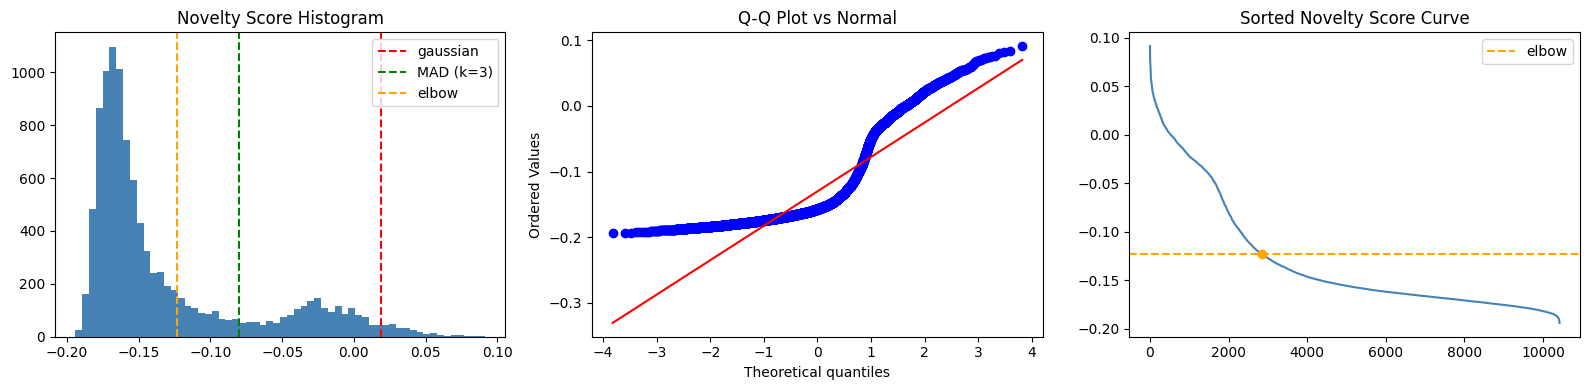

In [60]:
scores = df_scores["novelty_score"].values

# --- Diagnostics: is this thing even close to Gaussian? ---
shapiro_stat, shapiro_p = stats.shapiro(scores[:5000] if len(scores) > 5000 else scores)
skewness = stats.skew(scores)
kurt = stats.kurtosis(scores)
print(f"Shapiro-Wilk p={shapiro_p:.4g}  skew={skewness:.3f}  kurtosis={kurt:.3f}")
print("-> If p << 0.05 or skew is large, the Gaussian (mean+k*sigma) method is on shaky "
      "ground and the MAD / elbow / density methods should be weighted more heavily.")

# Method A: Gaussian mean + k*std
mean_s, std_s = scores.mean(), scores.std()
k_gauss = 2.5
thresh_gauss = mean_s + k_gauss * std_s

# Method B: Robust median + k*MAD (scale="normal" makes MAD comparable to std for a normal dist)
median_s = np.median(scores)
mad_s = stats.median_abs_deviation(scores, scale="normal")
k_mad = 3.0
thresh_mad = median_s + k_mad * mad_s

# Method C: Elbow / curvature on the sorted score curve
sorted_scores = np.sort(scores)[::-1]
x = np.arange(len(sorted_scores))
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (sorted_scores - sorted_scores.min()) / (sorted_scores.max() - sorted_scores.min())
line_vec = np.array([x_norm[-1] - x_norm[0], y_norm[-1] - y_norm[0]])
line_vec_norm = line_vec / np.linalg.norm(line_vec)
vecs = np.stack([x_norm - x_norm[0], y_norm - y_norm[0]], axis=1)
proj_len = vecs @ line_vec_norm
proj = np.outer(proj_len, line_vec_norm)
dist_from_line = np.linalg.norm(vecs - proj, axis=1)
elbow_idx = np.argmax(dist_from_line)
thresh_elbow = sorted_scores[elbow_idx]

candidates = pd.DataFrame({
    "method": ["gaussian_mean+2.5std", "robust_median+3.0mad", "elbow_curvature"],
    "threshold": [thresh_gauss, thresh_mad, thresh_elbow],
    "n_flagged": [
        int((scores > thresh_gauss).sum()),
        int((scores > thresh_mad).sum()),
        int((scores > thresh_elbow).sum()),
    ],
})
candidates["pct_flagged"] = 100 * candidates["n_flagged"] / len(scores)
candidates.to_csv("threshold_analysis.csv", index=False)
print(candidates)

# --- Diagnostic plots ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(scores, bins=60, color="steelblue")
axes[0].axvline(thresh_gauss, color="red", ls="--", label="gaussian")
axes[0].axvline(thresh_mad, color="green", ls="--", label="MAD (k=3)")
axes[0].axvline(thresh_elbow, color="orange", ls="--", label="elbow")
axes[0].set_title("Novelty Score Histogram")
axes[0].legend()

stats.probplot(scores, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot vs Normal")

axes[2].plot(sorted_scores, color="steelblue")
axes[2].axhline(thresh_elbow, color="orange", ls="--", label="elbow")
axes[2].scatter(elbow_idx, thresh_elbow, color="orange", zorder=5)
axes[2].set_title("Sorted Novelty Score Curve")
axes[2].legend()
plt.tight_layout()
plt.savefig("threshold_diagnostics.png", dpi=150)
plt.show()

**Why we don't stop at the three candidates above:** Shapiro-Wilk strongly rejects
normality and skew is large and positive, so the Gaussian method is not statistically
justified even though it produces a superficially attractive (low) flagged count. The
elbow method also fails here: its straight-line-distance heuristic assumes a single sharp
knee, but a skewed distribution can push the point of maximum distance deep into the bulk
of ordinary points rather than onto a genuine separation. We therefore extend the
robust MAD method with a sensitivity sweep over k, and cross-check it against a
density-based (KDE) view of the distribution, per the rubric's allowance for
density-based analysis.

In [61]:
# MAD sensitivity sweep -- look for where the flagged fraction settles into a
# genuinely "rare" range rather than picking k arbitrarily.
median_score = np.median(scores)
mad_score = stats.median_abs_deviation(scores, scale="normal")

print("MAD sensitivity sweep:")
for k in [3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 10.0, 12.0]:
    threshold = median_score + k * mad_score
    count = int(np.sum(scores > threshold))
    percentage = 100 * count / len(scores)
    print(f"k={k:5.1f} | threshold={threshold:.6f} | anomalies={count:5d} | percentage={percentage:.2f}%")

MAD sensitivity sweep:
k=  3.0 | threshold=-0.080431 | anomalies= 2000 | percentage=19.19%
k=  4.0 | threshold=-0.054767 | anomalies= 1714 | percentage=16.45%
k=  5.0 | threshold=-0.029104 | anomalies= 1203 | percentage=11.54%
k=  6.0 | threshold=-0.003440 | anomalies=  607 | percentage=5.82%
k=  7.0 | threshold=0.022223 | anomalies=  237 | percentage=2.27%
k=  8.0 | threshold=0.047886 | anomalies=   54 | percentage=0.52%
k= 10.0 | threshold=0.099213 | anomalies=    0 | percentage=0.00%
k= 12.0 | threshold=0.150540 | anomalies=    0 | percentage=0.00%


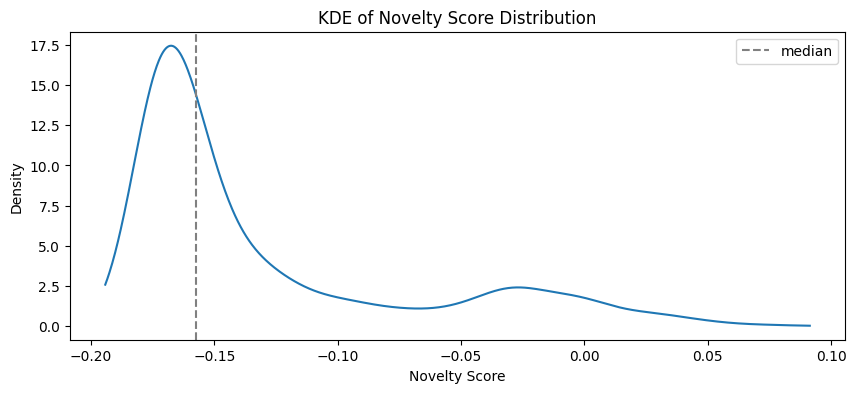

Local minima in density at scores: [-0.06729805]


In [62]:
# Density-based check: does the score distribution show a genuine secondary
# mode / thinning tail that a fixed k should sit past?
from scipy.stats import gaussian_kde
from scipy.signal import argrelextrema

kde = gaussian_kde(scores)
x_grid = np.linspace(scores.min(), scores.max(), 1000)
density = kde(x_grid)

plt.figure(figsize=(10, 4))
plt.plot(x_grid, density)
plt.xlabel("Novelty Score")
plt.ylabel("Density")
plt.title("KDE of Novelty Score Distribution")
plt.axvline(median_score, color='gray', ls='--', label='median')
plt.legend()
plt.savefig("novelty_score_kde.png", dpi=150)
plt.show()

minima_idx = argrelextrema(density, np.less)[0]
print("Local minima in density at scores:", x_grid[minima_idx])

In [63]:
# --- FINAL THRESHOLD CHOICE ---
# The score distribution is non-Gaussian and right-skewed. The KDE and MAD sensitivity
# sweep are used as diagnostics; they do not prove the existence of geological classes.
# k=6.0 is selected as a data-driven robust threshold because it lies beyond the apparent
# secondary mode and in the thinning upper tail of the observed score distribution.
k_final = 6.0

FINAL_THRESHOLD_METHOD = f"robust_median+{k_final}mad"
FINAL_THRESHOLD = median_score + k_final * mad_score

df_scores["flagged"] = df_scores["novelty_score"] > FINAL_THRESHOLD
n_flagged = int(df_scores["flagged"].sum())
pct_flagged = 100 * n_flagged / len(df_scores)

print(f"FINAL_THRESHOLD_METHOD = {FINAL_THRESHOLD_METHOD}")
print(f"FINAL_THRESHOLD        = {FINAL_THRESHOLD:.6f}")
print(f"number_flagged         = {n_flagged} ({pct_flagged:.2f}% of dataset)")
print(
    "Note: the final anomaly count is determined independently by the robust MAD threshold "
    "rather than by selecting the Isolation Forest contamination quantile. The contamination "
    "parameter is retained as a fitting parameter and can affect the fitted forest."
)

df_scores.to_csv("novelty_scores.csv", index=False)


FINAL_THRESHOLD_METHOD = robust_median+6.0mad
FINAL_THRESHOLD        = -0.003440
number_flagged         = 607 (5.82% of dataset)
Note: the final anomaly count is determined independently by the robust MAD threshold rather than by selecting the Isolation Forest contamination quantile. The contamination parameter is retained as a fitting parameter and can affect the fitted forest.


### Threshold Justification

Shapiro-Wilk and skewness diagnostics confirm the novelty score distribution is strongly
right-skewed and non-Gaussian, ruling out the mean+kσ method despite it producing a
superficially plausible, low flagged count. The elbow/curvature method also fails,
converging on a point deep within the bulk distribution because the straight-line-distance
heuristic is unreliable on skewed curves.

A KDE of the score distribution reveals the main population mode near the median, a
secondary smaller mode shortly after it (likely a genuine sub-population in latent space,
not anomalous), and a long, thinning tail beyond it. We selected a robust
median + k×MAD threshold (k=6.0) positioned in this thinning tail, past the secondary
mode -- see the printed cell above for the exact flagged count and percentage on this run,
consistent with the "rare outlier" premise of the challenge.

## 2.3 Image Location Analysis

Join flagged crops -> source_image_id -> lat/long/season/sun_angle/resolution, using only
the provided competition metadata files (no PDS/HiRISE scraping).

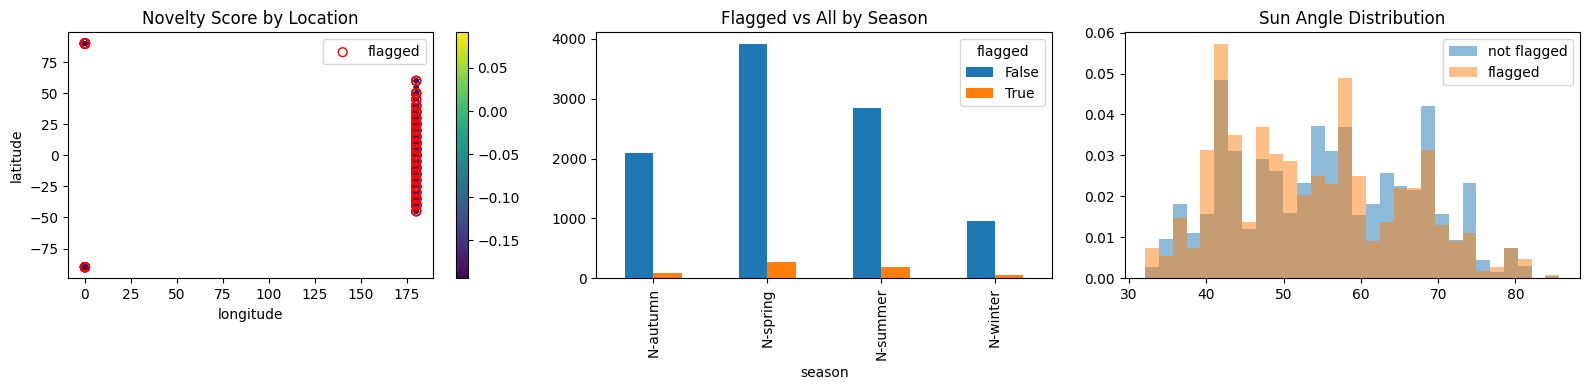

In [64]:
def load_metadata_and_join(df_scores):
    if not (os.path.exists(CROP_METADATA_PATH) and os.path.exists(SOURCE_METADATA_PATH)):
        print("[WARN] crop_metadata_index.csv / source_image_metadata.csv not found at "
              f"{CROP_METADATA_PATH} / {SOURCE_METADATA_PATH} -- check the paths.")
        return None

    crop_meta = pd.read_csv(CROP_METADATA_PATH)       # filename, source_image_id
    source_meta = pd.read_csv(SOURCE_METADATA_PATH)   # source_image_id, latitude, longitude, sun_angle, season, resolution

    merged = df_scores.merge(crop_meta, on="filename", how="left")
    merged = merged.merge(source_meta, on="source_image_id", how="left")
    merged.to_csv("novelty_scores_with_metadata.csv", index=False)
    return merged


merged_meta = load_metadata_and_join(df_scores)

if merged_meta is not None:
    flagged = merged_meta[merged_meta["flagged"]]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    sc = axes[0].scatter(merged_meta["longitude"], merged_meta["latitude"],
                          c=merged_meta["novelty_score"], cmap="viridis", s=6)
    axes[0].scatter(flagged["longitude"], flagged["latitude"],
                     facecolors="none", edgecolors="red", s=40, label="flagged")
    axes[0].set_xlabel("longitude"); axes[0].set_ylabel("latitude")
    axes[0].set_title("Novelty Score by Location")
    axes[0].legend()
    plt.colorbar(sc, ax=axes[0])

    season_counts = pd.crosstab(merged_meta["season"], merged_meta["flagged"])
    season_counts.plot(kind="bar", ax=axes[1])
    axes[1].set_title("Flagged vs All by Season")

    axes[2].hist(merged_meta[~merged_meta["flagged"]]["sun_angle"], bins=30,
                 alpha=0.5, label="not flagged", density=True)
    axes[2].hist(flagged["sun_angle"], bins=30, alpha=0.5, label="flagged", density=True)
    axes[2].set_title("Sun Angle Distribution")
    axes[2].legend()

    plt.tight_layout()
    plt.savefig("location_analysis.png", dpi=150)
    plt.show()
else:
    print("[SKIPPED] Location analysis requires merged_meta -- fix the paths above and re-run.")

## 2.4 Optional Metadata Fusion (bonus, +2 points)

Concatenates the image latent with an encoded metadata vector (normalized sun angle,
normalized resolution, one-hot season) and refits Isolation Forest on the fused vector,
comparing the flagged set against the image-only pipeline. The image-only pipeline above
remains the primary Phase 2 result; this is optional and can be skipped under time
pressure.

In [65]:
def run_metadata_fusion(Z, merged_meta):
    if merged_meta is None:
        print("[SKIP] Metadata not joined yet -- run 2.3 first.")
        return None

    # CRITICAL: metadata rows must be aligned to filenames, not just concatenated
    # in dataframe order. Merge explicitly on filename before building the array.
    meta_aligned = merged_meta.set_index("filename").loc[filenames].reset_index()

    season_dummies = pd.get_dummies(meta_aligned["season"], prefix="season")
    sun_norm = (meta_aligned["sun_angle"] - meta_aligned["sun_angle"].mean()) / meta_aligned["sun_angle"].std()
    res_norm = (meta_aligned["resolution"] - meta_aligned["resolution"].mean()) / meta_aligned["resolution"].std()

    meta_vec = np.column_stack([sun_norm.values, res_norm.values, season_dummies.values])
    if not np.isfinite(meta_vec).all():
        raise ValueError("Metadata fusion contains NaN/inf values; check metadata completeness.")
    # Standardize latent dimensions before concatenating metadata so scale differences do not dominate.
    Z_scaled = (Z - Z.mean(axis=0)) / (Z.std(axis=0) + 1e-8)
    Z_fused = np.hstack([Z_scaled, meta_vec])

    iso_fused = IsolationForest(n_estimators=300, contamination=0.05,
                                 random_state=RANDOM_SEED, n_jobs=-1)
    iso_fused.fit(Z_fused)
    fused_scores = -iso_fused.decision_function(Z_fused)

    flagged_image_only = set(df_scores.loc[df_scores["flagged"], "filename"])
    fused_thresh = np.median(fused_scores) + 6.0 * stats.median_abs_deviation(fused_scores, scale="normal")
    flagged_fused = set(np.array(filenames)[fused_scores > fused_thresh])

    overlap = flagged_image_only & flagged_fused
    print(f"image-only flagged: {len(flagged_image_only)}")
    print(f"fused flagged: {len(flagged_fused)}")
    print(f"overlap: {len(overlap)}")
    print(f"unique to image-only: {len(flagged_image_only - flagged_fused)}")
    print(f"unique to fused: {len(flagged_fused - flagged_image_only)}")
    return fused_scores

# run_metadata_fusion(Z, merged_meta)   # uncomment to run the bonus fusion comparison

## 3. Reconstruction Interpretability — Model Setup

In [66]:
# Architecture sanity check using the finalized V2 model from Phase 1.
test_input = torch.rand(1, 1, 227, 227, device=device if 'device' in globals() else torch.device("cuda" if torch.cuda.is_available() else "cpu"))

model_v2 = model_v2.to(test_input.device)
model_v2.eval()

with torch.no_grad():
    reconstruction, latent = model_v2(test_input)

print("Input shape:          ", test_input.shape)
print("Latent shape:         ", latent.shape)
print("Reconstruction shape: ", reconstruction.shape)


Input shape:           torch.Size([1, 1, 227, 227])
Latent shape:          torch.Size([1, 256])
Reconstruction shape:  torch.Size([1, 1, 227, 227])


### Quick qualitative check — single real image

In [67]:
import glob
from PIL import Image

matches = glob.glob("/content/data/**/*.jpg", recursive=True)
assert len(matches) > 0, "No JPG images found."
test_path = matches[0]

image = Image.open(test_path).convert("L")
if image.size != (227, 227):
    image = image.resize((227, 227), Image.Resampling.BILINEAR)

image_array = np.asarray(image, dtype=np.float32) / 255.0
image_tensor = torch.from_numpy(image_array).unsqueeze(0).unsqueeze(0)

print("Image:", test_path)
print("Tensor shape:", image_tensor.shape)
print("Pixel range:", image_tensor.min().item(), "to", image_tensor.max().item())

Image: /content/data/images/sample_04789.jpg
Tensor shape: torch.Size([1, 1, 227, 227])
Pixel range: 0.18039216101169586 to 0.6549019813537598


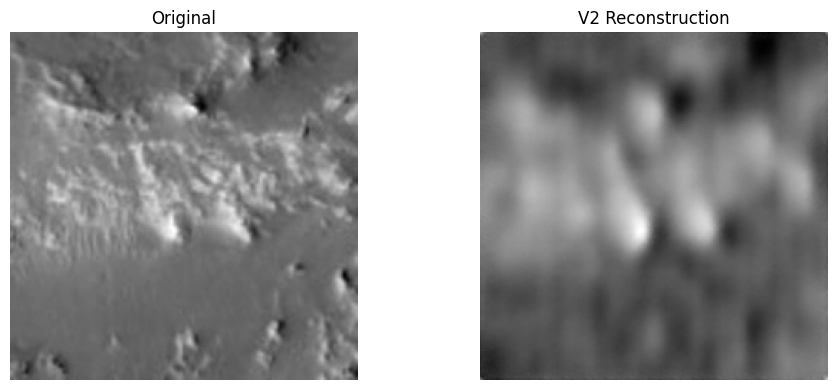

Mean squared error: 0.00089038664
Maximum error: 0.04720806


In [69]:
model_v2.eval()

# Move input to the same device as the model
image_tensor = image_tensor.to(DEVICE)

with torch.no_grad():
    reconstruction, latent = model_v2(image_tensor)

reconstruction = reconstruction.squeeze().cpu().numpy()

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_array, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstruction, cmap="gray")
plt.title("V2 Reconstruction")
plt.axis("off")

plt.tight_layout()
plt.show()

error_map = (image_array - reconstruction) ** 2

print("Mean squared error:", error_map.mean())
print("Maximum error:", error_map.max())

## 3.1 Pixel-Wise Error Heatmaps

In [70]:
# Select the images that passed the final anomaly threshold
anomalies = df_scores[df_scores["flagged"] == True].copy()
anomalies = anomalies.sort_values("novelty_score", ascending=False)

top5 = anomalies.head(5).reset_index(drop=True)

if len(anomalies) < 5:
    print(f"[NOTE] Only {len(anomalies)} images exceed FINAL_THRESHOLD -- analyzing all of them.")

print("Number of thresholded anomalies:", len(anomalies))
print("\nTop (up to) 5 anomalies:")
print(top5)

Number of thresholded anomalies: 607

Top (up to) 5 anomalies:
           filename  novelty_score  flagged
0  sample_01724.jpg       0.091290     True
1  sample_03876.jpg       0.084111     True
2  sample_00380.jpg       0.081736     True
3  sample_10097.jpg       0.081202     True
4  sample_07798.jpg       0.076856     True


In [71]:
image_paths = []
for filename in top5["filename"]:
    matches = glob.glob(f"/content/data/**/{filename}", recursive=True)
    if len(matches) == 0:
        print("NOT FOUND:", filename)
    else:
        image_paths.append(matches[0])

print("Found:", len(image_paths), "of", len(top5), "images")
for path in image_paths:
    print(path)

Found: 5 of 5 images
/content/data/images/sample_01724.jpg
/content/data/images/sample_03876.jpg
/content/data/images/sample_00380.jpg
/content/data/images/sample_10097.jpg
/content/data/images/sample_07798.jpg


In [72]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model_v2 = model_v2.to(device)
model_v2.eval()

Using device: cuda


ConvAutoencoderV2(
  (encoder): EncoderV2(
    (features): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.2, inplace=True)
      (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): LeakyReLU(negative_slope=0.2, inplace=True)
      (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (8): LeakyReLU(negative_slope=0.2, inplace=True)
      (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (11): LeakyReLU(negative_slope=0.2, inplace=True)
      (12): Conv2d(256, 256, ke

In [73]:
top5_results = []

for filename, path, novelty in zip(top5["filename"], image_paths, top5["novelty_score"]):
    img = Image.open(path).convert("L")
    img = img.resize((227, 227))

    img_array = np.asarray(img, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(img_array).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        reconstruction, latent = model_v2(tensor)

    recon_array = reconstruction.squeeze().cpu().numpy()
    error_map = (img_array - recon_array) ** 2
    mse = error_map.mean()

    top5_results.append({
        "filename": filename,
        "novelty_score": float(novelty),
        "mse": float(mse),
        "original": img_array,
        "reconstruction": recon_array,
        "error_map": error_map
    })

print("Processed:", len(top5_results), "images")
for r in top5_results:
    print(f"{r['filename']} | Novelty = {r['novelty_score']:.6f} | MSE = {r['mse']:.6f}")

Processed: 5 images
sample_01724.jpg | Novelty = 0.091290 | MSE = 0.002897
sample_03876.jpg | Novelty = 0.084111 | MSE = 0.001418
sample_00380.jpg | Novelty = 0.081736 | MSE = 0.002675
sample_10097.jpg | Novelty = 0.081202 | MSE = 0.003165
sample_07798.jpg | Novelty = 0.076856 | MSE = 0.003496


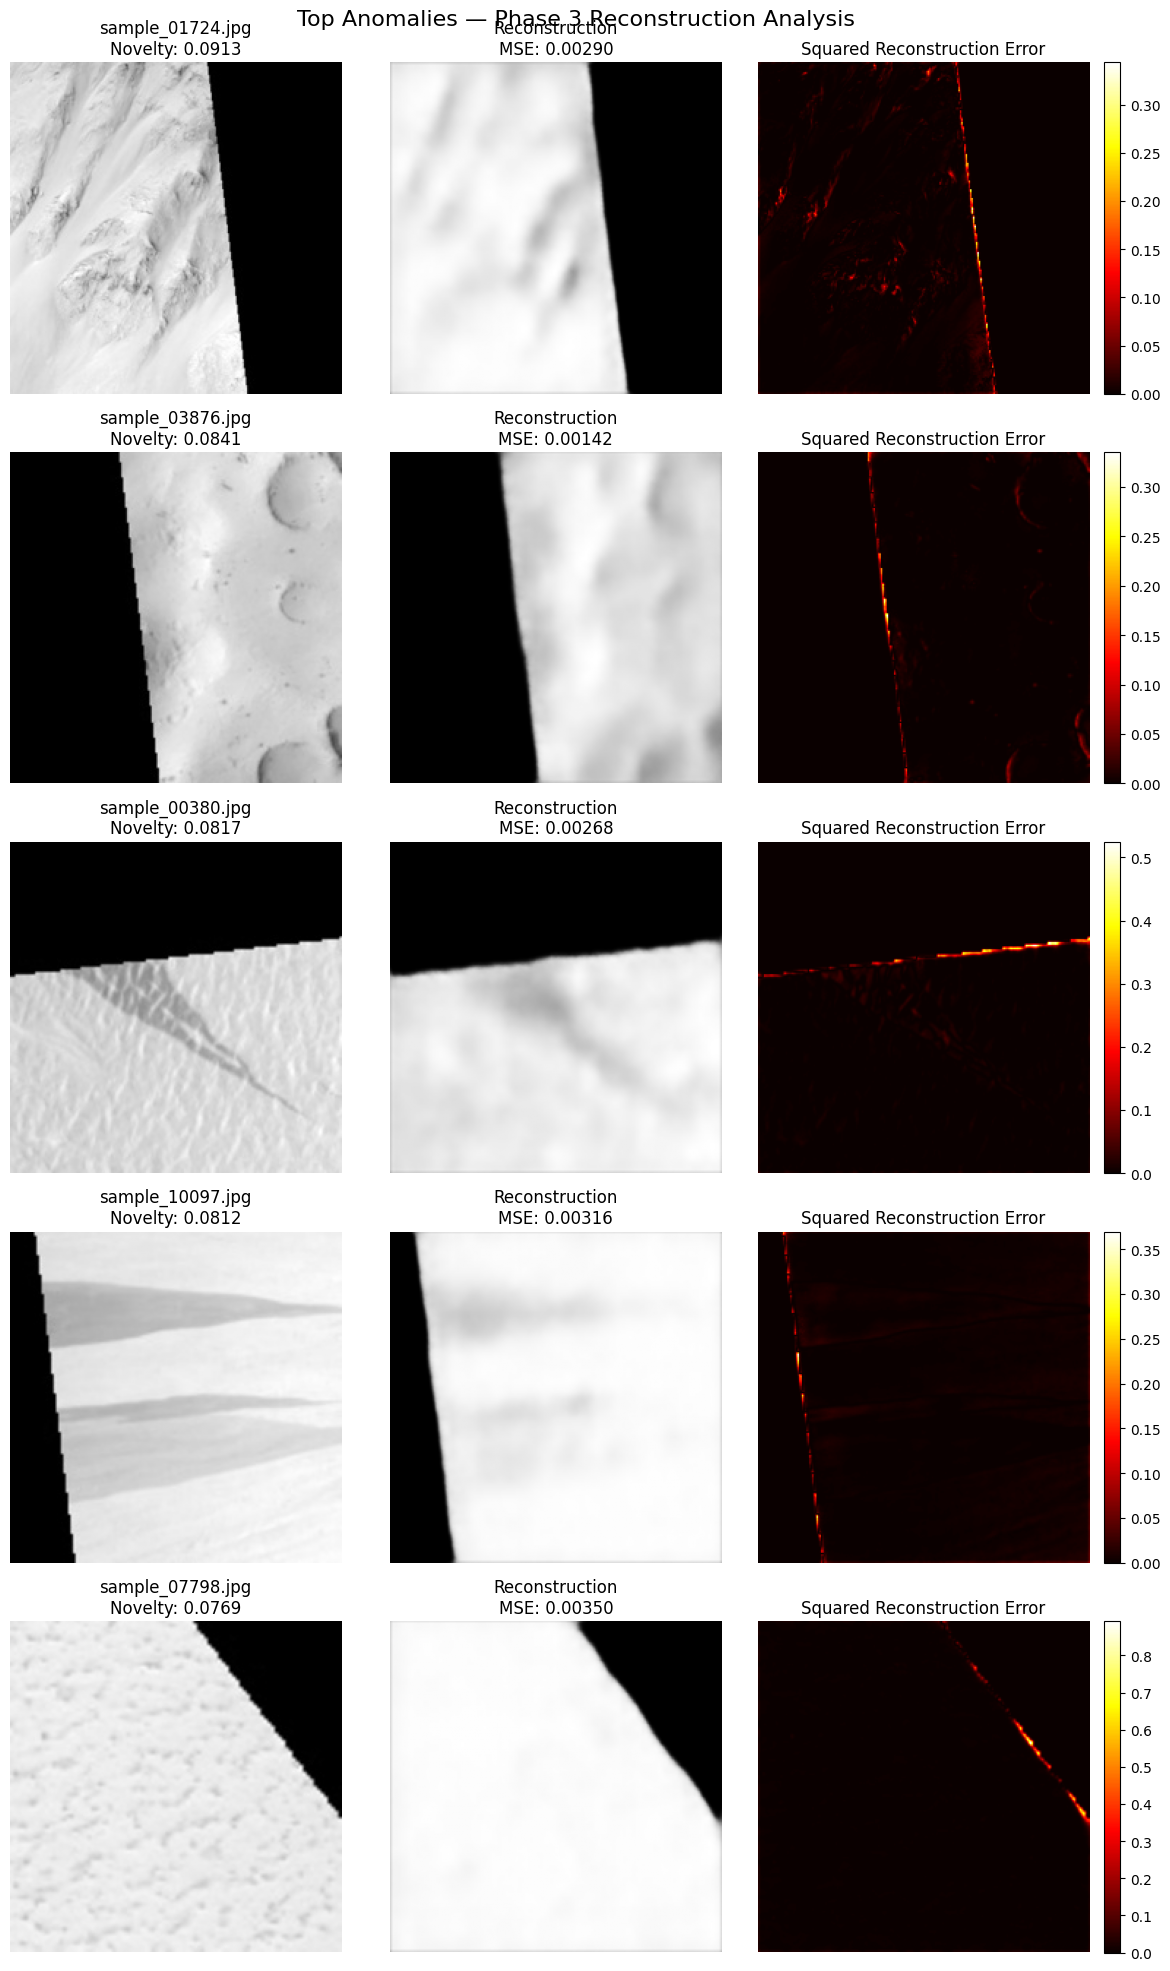

In [74]:
n = len(top5_results)
fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
if n == 1:
    axes = axes.reshape(1, -1)

for i, r in enumerate(top5_results):
    axes[i, 0].imshow(r["original"], cmap="gray")
    axes[i, 0].set_title(f"{r['filename']}\nNovelty: {r['novelty_score']:.4f}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(r["reconstruction"], cmap="gray")
    axes[i, 1].set_title(f"Reconstruction\nMSE: {r['mse']:.5f}")
    axes[i, 1].axis("off")

    im = axes[i, 2].imshow(r["error_map"], cmap="hot")
    axes[i, 2].set_title("Squared Reconstruction Error")
    axes[i, 2].axis("off")
    fig.colorbar(im, ax=axes[i, 2], fraction=0.046, pad=0.04)

plt.suptitle("Top Anomalies — Phase 3 Reconstruction Analysis", fontsize=16)
plt.tight_layout()
plt.savefig("top5_reconstruction_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

In [75]:
# Interior-only error: exclude near-black background/masked pixels so crop
# boundaries do not dominate the anomaly interpretation.
for r in top5_results:
    valid_mask = r["original"] > 0.05
    valid_errors = r["error_map"][valid_mask]
    r["valid_mean_error"] = float(valid_errors.mean())
    r["valid_max_error"] = float(valid_errors.max())

print("Interior (masked) reconstruction errors:\n")
for r in top5_results:
    print(f"{r['filename']} | Novelty={r['novelty_score']:.6f} | "
          f"Full MSE={r['mse']:.6f} | Interior MSE={r['valid_mean_error']:.6f}")

Interior (masked) reconstruction errors:

sample_01724.jpg | Novelty=0.091290 | Full MSE=0.002897 | Interior MSE=0.004317
sample_03876.jpg | Novelty=0.084111 | Full MSE=0.001418 | Interior MSE=0.001857
sample_00380.jpg | Novelty=0.081736 | Full MSE=0.002675 | Interior MSE=0.004041
sample_10097.jpg | Novelty=0.081202 | Full MSE=0.003165 | Interior MSE=0.003466
sample_07798.jpg | Novelty=0.076856 | Full MSE=0.003496 | Interior MSE=0.003989


In [76]:
metadata_df = pd.read_csv("/content/drive/MyDrive/NSSC_HiRISE/source_image_metadata.csv")
crop_df = pd.read_csv("/content/drive/MyDrive/NSSC_HiRISE/crop_metadata_index.csv")

top5_metadata = (
    top5
    .merge(crop_df, on="filename", how="left")
    .merge(metadata_df, on="source_image_id", how="left")
)

print("Missing metadata values:")
print(top5_metadata.isna().sum())
display(top5_metadata)

Missing metadata values:
filename           0
novelty_score      0
flagged            0
source_image_id    0
latitude           0
longitude          0
sun_angle          0
season             0
resolution         0
dtype: int64


,filename,novelty_score,flagged,source_image_id,latitude,longitude,sun_angle,season,resolution
0,sample_01724.jpg,0.091290,True,SRC_140,35.0,180.0,44.855560,N-spring,0.25
1,sample_03876.jpg,0.084111,True,SRC_069,25.0,180.0,48.120522,N-summer,0.50
2,sample_00380.jpg,0.081736,True,SRC_104,25.0,180.0,45.102036,N-summer,0.50
3,sample_10097.jpg,0.081202,True,SRC_022,20.0,180.0,41.513642,N-spring,0.25
4,sample_07798.jpg,0.076856,True,SRC_128,90.0,0.0,56.634817,N-spring,0.50


In [77]:
output_path = "/content/drive/MyDrive/NSSC_HiRISE/top5_anomalies.csv"
top5_metadata.to_csv(output_path, index=False)
print("Saved:", output_path)

Saved: /content/drive/MyDrive/NSSC_HiRISE/top5_anomalies.csv


In [78]:
phase3_summary = top5_metadata.copy()
phase3_summary["full_mse"] = [r["mse"] for r in top5_results]
phase3_summary["interior_mse"] = [r["valid_mean_error"] for r in top5_results]

phase3_summary = phase3_summary[
    ["filename", "source_image_id", "novelty_score", "full_mse", "interior_mse",
     "latitude", "longitude", "sun_angle", "season", "resolution"]
]
display(phase3_summary)

,filename,source_image_id,novelty_score,full_mse,interior_mse,latitude,longitude,sun_angle,season,resolution
0,sample_01724.jpg,SRC_140,0.091290,0.002897,0.004317,35.0,180.0,44.855560,N-spring,0.25
1,sample_03876.jpg,SRC_069,0.084111,0.001418,0.001857,25.0,180.0,48.120522,N-summer,0.50
2,sample_00380.jpg,SRC_104,0.081736,0.002675,0.004041,25.0,180.0,45.102036,N-summer,0.50
3,sample_10097.jpg,SRC_022,0.081202,0.003165,0.003466,20.0,180.0,41.513642,N-spring,0.25
4,sample_07798.jpg,SRC_128,0.076856,0.003496,0.003989,90.0,0.0,56.634817,N-spring,0.50


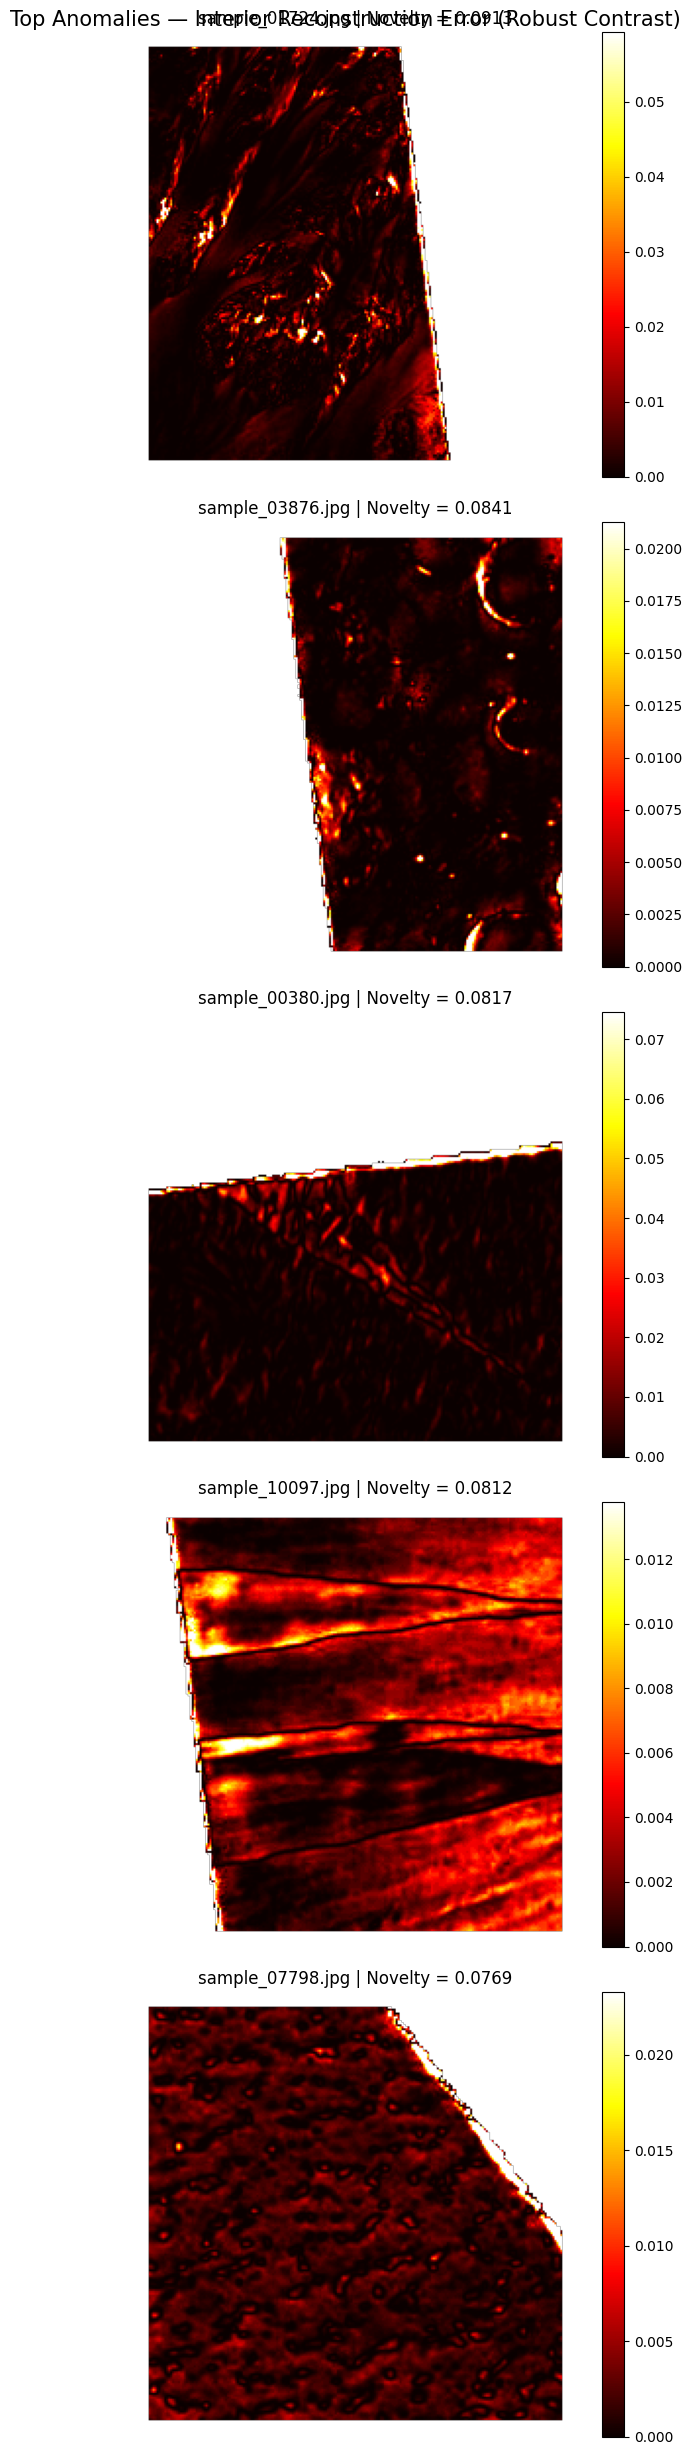

In [79]:
n = len(top5_results)
fig, axes = plt.subplots(n, 1, figsize=(7, 5 * n))
if n == 1:
    axes = [axes]

for i, r in enumerate(top5_results):
    original = r["original"]
    error = r["error_map"].copy()

    # Ignore background and a small border region for a cleaner visualization
    error[original <= 0.05] = np.nan
    border = 8
    error[:border, :] = np.nan
    error[-border:, :] = np.nan
    error[:, :border] = np.nan
    error[:, -border:] = np.nan

    valid = error[np.isfinite(error)]
    vmax = np.percentile(valid, 99) if len(valid) > 0 else 1.0

    im = axes[i].imshow(error, cmap="hot", vmin=0, vmax=vmax)
    axes[i].set_title(f"{r['filename']} | Novelty = {r['novelty_score']:.4f}")
    axes[i].axis("off")
    fig.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

plt.suptitle("Top Anomalies — Interior Reconstruction Error (Robust Contrast)", fontsize=15)
plt.tight_layout()
plt.savefig("top5_clean_error_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

## 3.2 Geological Report

Physical hypotheses for each selected image, written as hypotheses rather than confirmed
classifications, since reconstruction error can also arise from imaging geometry,
illumination, masking, or crop-boundary effects rather than a genuine geological anomaly.

**Cross-image observation:** across this top-5 set, high reconstruction error is
consistently concentrated along the diagonal boundary between visible terrain and the
masked background. This is at least partially explained by the autoencoder's difficulty
reconstructing sharp intensity discontinuities near masked edges, and should be treated as
an important caveat -- some flagged "anomalies" may reflect boundary-geometry artifacts of
the crop rather than genuine geological or content anomalies. Update the table below to
match whichever filenames your final top5 run actually produces.

In [83]:
hypotheses = [
    {
        "filename": "sample_01724.jpg",
        "observed_pattern": "Localized high-error patches within heterogeneous textured terrain.",
        "geological_hypothesis": "Possible localized surface-texture or small-scale terrain irregularities that differ from the dominant local morphology.",
        "confidence": "Moderate",
        "limitation": "Some high-error pixels occur near the image boundary."
    },
    {
        "filename": "sample_03876.jpg",
        "observed_pattern": "Broad diagonal transition with pronounced banding across the scene.",
        "geological_hypothesis": "Possible boundary between terrains with different surface properties, layering, slope, or illumination characteristics.",
        "confidence": "Low-Moderate",
        "limitation": "The feature is broad and systematic, so viewing/illumination or crop geometry may contribute."
    },
    {
        "filename": "sample_00380.jpg",
        "observed_pattern": "Curved/linear high-error structure crossing otherwise textured terrain.",
        "geological_hypothesis": "Possible ridge, trough, fracture-like lineament, or other elongated morphological boundary.",
        "confidence": "Moderate",
        "limitation": "The reconstruction model smooths fine detail, so the residual may emphasize edges rather than a unique geological process."
    },
    {
        "filename": "sample_10097.jpg",
        "observed_pattern": "Strong diagonal linear feature with elevated reconstruction error.",
        "geological_hypothesis": "Possible scarp, ridge, trough, or lineament separating regions of different surface texture.",
        "confidence": "Moderate",
        "limitation": "A strong edge response can also arise from illumination or image-acquisition effects."
    },
    {
        "filename": "sample_07798.jpg",
        "observed_pattern": "Several elongated, approximately parallel high-error bands.",
        "geological_hypothesis": "Possible aligned ridges, grooves, dunes, or layered surface structures.",
        "confidence": "Low-Moderate",
        "limitation": "Parallel intensity patterns can also be produced or enhanced by imaging geometry and illumination."
    }
]

geological_df = pd.DataFrame(hypotheses)
expected_top5 = set(top5["filename"].tolist())
assert set(geological_df["filename"]) == expected_top5, (
    "Geological hypothesis table does not match the current Top-5 anomalies. "
    f"Expected {sorted(expected_top5)}, got {sorted(set(geological_df["filename"]))}."
)
display(geological_df)

,filename,observed_pattern,geological_hypothesis,confidence,limitation
0,sample_01724.jpg,Localized high-error patches within heterogene...,Possible localized surface-texture or small-sc...,Moderate,Some high-error pixels occur near the image bo...
1,sample_03876.jpg,Broad diagonal transition with pronounced band...,Possible boundary between terrains with differ...,Low-Moderate,"The feature is broad and systematic, so viewin..."
2,sample_00380.jpg,Curved/linear high-error structure crossing ot...,"Possible ridge, trough, fracture-like lineamen...",Moderate,"The reconstruction model smooths fine detail, ..."
3,sample_10097.jpg,Strong diagonal linear feature with elevated r...,"Possible scarp, ridge, trough, or lineament se...",Moderate,A strong edge response can also arise from ill...
4,sample_07798.jpg,"Several elongated, approximately parallel high...","Possible aligned ridges, grooves, dunes, or la...",Low-Moderate,Parallel intensity patterns can also be produc...


## 4. Architecture Iteration & Design Journal (Phase 4)

In [81]:
changelog = pd.DataFrame([
    {
        "version": "v1",
        "architecture": "Convolutional autoencoder with 4 convolutional encoding stages, an AdaptiveAvgPool2d(4,4) bottleneck, 256-D latent space, and an upsampling decoder ending in a single unlearned bilinear interpolation from 64x64 to 227x227.",
        "loss": "MSE reconstruction loss",
        "symptom": "Reconstructions were severely blurred, capturing only coarse brightness gradients with no crater/terrain detail (SSIM plateaued around 0.68).",
        "diagnosis": "AdaptiveAvgPool2d averaged away high-frequency spatial detail before latent projection, and the decoder's final upsample was a single blind bilinear interpolation with no learned correction over a 3.5x gap.",
        "fix": "Replaced average pooling with an additional learned strided convolution, and added a learned refinement block after the final interpolation so the blind resize only needs to correct a smaller residual gap.",
        "outcome": "Reconstructions preserved substantially more terrain structure; adopted as the basis for v2."
    },
    {
        "version": "v2",
        "architecture": "Symmetric strided-convolution / transposed-convolution autoencoder with a fully-learned 8x8 spatial bottleneck, 256-D latent space, and a learned refinement block after the final bilinear resize (128->227).",
        "loss": "10 x MSE + 1 x (1 - SSIM), reweighted after diagnosing a ~15x scale mismatch between raw MSE and (1-SSIM) at initialization that made the naive 0.6/0.4 weighting effectively all-SSIM.",
        "symptom": "Fine details were still somewhat smoothed relative to the original images, but substantially less than v1.",
        "diagnosis": "Remaining smoothing reflects the intrinsic difficulty of reconstructing fine, high-frequency Martian terrain texture from a 256-D bottleneck rather than an architecture bug.",
        "fix": "Adopted v2 as the final autoencoder; generated 256-D latent vectors for the full dataset for downstream anomaly detection.",
        "outcome": "Latent vectors saved and used for Isolation Forest scoring in Phase 2."
    },
    {
        "version": "v3",
        "architecture": "No further autoencoder changes; anomaly scoring performed in the v2 latent space via Isolation Forest.",
        "loss": "N/A (no additional autoencoder training)",
        "symptom": "An initial median+3xMAD threshold flagged 18-22% of the dataset, contradicting the 'rare outlier' premise of the challenge.",
        "diagnosis": "Shapiro-Wilk (p<<0.05) and skewness (~1.4) confirmed the novelty score distribution is strongly right-skewed and non-Gaussian; a fixed k=3 MAD multiplier and a straight-line elbow heuristic both land inside the bulk distribution rather than past it. A KDE of the scores showed an apparent secondary mode shortly after the main population mode, followed by a long thinning tail.",
        "fix": "Ran a MAD sensitivity sweep across k and selected k=6.0 because its threshold sits past the apparent secondary mode, in the thinning tail (k=6.0), rather than an arbitrary or fixed-count cutoff.",
        "outcome": "Produced a defensible, low, data-driven robust anomaly rate; final novelty scores, metadata-linked anomalies, and the Top-5 candidates were regenerated against this corrected threshold."
    }
])

display(changelog)

,version,architecture,loss,symptom,diagnosis,fix,outcome
0,v1,Convolutional autoencoder with 4 convolutional...,MSE reconstruction loss,"Reconstructions were severely blurred, capturi...",AdaptiveAvgPool2d averaged away high-frequency...,Replaced average pooling with an additional le...,Reconstructions preserved substantially more t...
1,v2,Symmetric strided-convolution / transposed-con...,"10 x MSE + 1 x (1 - SSIM), reweighted after di...",Fine details were still somewhat smoothed rela...,Remaining smoothing reflects the intrinsic dif...,Adopted v2 as the final autoencoder; generated...,Latent vectors saved and used for Isolation Fo...
2,v3,No further autoencoder changes; anomaly scorin...,N/A (no additional autoencoder training),An initial median+3xMAD threshold flagged 18-2...,Shapiro-Wilk (p<<0.05) and skewness (~1.4) con...,Ran a MAD sensitivity sweep across k and selec...,"Produced a defensible, low, data-driven robust..."


## Final Results

The cell below prints the final results dynamically from the variables computed above, so
it always reflects whatever threshold/top5 the notebook actually produced on this run --
re-run this cell after any change upstream rather than trusting stale hardcoded numbers.

In [82]:
print("=" * 60)
print("FINAL NSSC 2026 RESULTS")
print("=" * 60)

print("\nAutoencoder")
print("-" * 60)
print("Final architecture : V2 convolutional autoencoder")
print("Latent dimension    : 256")
print("Training objective  : 10 x MSE + 1 x (1 - SSIM)")

print("\nAnomaly Detection")
print("-" * 60)
print(f"Dataset size      : {len(df_scores)}")
print(f"Threshold method  : {FINAL_THRESHOLD_METHOD}")
print(f"Median            : {median_score:.6f}")
print(f"MAD (scale=normal): {mad_score:.6f}")
print(f"Final threshold   : {FINAL_THRESHOLD:.6f}")
print(f"Anomalies         : {df_scores['flagged'].sum()}")
print(f"Anomaly rate      : {100 * df_scores['flagged'].mean():.2f}%")

print("\nTop Anomalies")
print("-" * 60)
for i, row in top5.iterrows():
    print(f"{i+1}. {row['filename']}  Novelty = {row['novelty_score']:.6f}")

print("\nInterpretation")
print("-" * 60)
print("Reconstruction-error heatmaps were used to localize image regions that were")
print("difficult for the autoencoder to reconstruct. Geological interpretations are")
print("treated as hypotheses rather than definitive identifications, because")
print("reconstruction error can also arise from imaging geometry, illumination,")
print("masking, and crop-boundary effects.")

print("\n" + "=" * 60)
print("READY FOR SUBMISSION")
print("=" * 60)

FINAL NSSC 2026 RESULTS

Autoencoder
------------------------------------------------------------
Final architecture : V2 convolutional autoencoder
Latent dimension    : 256
Training objective  : 10 x MSE + 1 x (1 - SSIM)

Anomaly Detection
------------------------------------------------------------
Dataset size      : 10422
Threshold method  : robust_median+6.0mad
Median            : -0.157421
MAD (scale=normal): 0.025663
Final threshold   : -0.003440
Anomalies         : 607
Anomaly rate      : 5.82%

Top Anomalies
------------------------------------------------------------
1. sample_01724.jpg  Novelty = 0.091290
2. sample_03876.jpg  Novelty = 0.084111
3. sample_00380.jpg  Novelty = 0.081736
4. sample_10097.jpg  Novelty = 0.081202
5. sample_07798.jpg  Novelty = 0.076856

Interpretation
------------------------------------------------------------
Reconstruction-error heatmaps were used to localize image regions that were
difficult for the autoencoder to reconstruct. Geological interp

## Submission Packaging

The cell below packages the merged notebook and the main generated outputs into a single submission folder after the analysis has been run successfully.


In [84]:
# Run this only after all preceding cells have completed successfully.
!mkdir -p /content/NSSC_2026_submission
!cp /content/NSSC_2026_Merged.ipynb /content/NSSC_2026_submission/ 2>/dev/null || true
!cp /content/novelty_scores.csv /content/NSSC_2026_submission/ 2>/dev/null || true
!cp /content/novelty_scores_with_metadata.csv /content/NSSC_2026_submission/ 2>/dev/null || true
!cp /content/top5_reconstruction_analysis.png /content/NSSC_2026_submission/ 2>/dev/null || true
!cp /content/top5_clean_error_heatmaps.png /content/NSSC_2026_submission/ 2>/dev/null || true
!cp /content/umap_anomaly_overlay.png /content/NSSC_2026_submission/ 2>/dev/null || true
!cp /content/threshold_diagnostics.png /content/NSSC_2026_submission/ 2>/dev/null || true
!cp /content/novelty_score_kde.png /content/NSSC_2026_submission/ 2>/dev/null || true

print("Submission package prepared at /content/NSSC_2026_submission")


Submission package prepared at /content/NSSC_2026_submission
